# Customer Churn Prediction & Strategic Risk Segmentation

# 1. Introduction

This project aims to predict customer churn for a large-scale e-commerce platform using a **Hybrid Intelligence** approach that combines Unsupervised Learning (Behavioral Clustering) with Supervised Learning.

Instead of merely predicting binary outcomes (Churn vs. Not Churn), this project focuses on **Actionable Intelligence**: transforming raw predictions into specific financial risk zones to optimize marketing ROI and prevent revenue loss.

The workflow is structured as follows:

1.  **Diagnostic EDA & Hypothesis Testing:** Rigorously testing 15 business hypotheses (e.g., "The Zombie Customer", "The Payment Friction") to identify deterministic churn drivers.

2.  **Strategic Preprocessing:** Implementing a robust "3-Way Split" (Train / Validation / Held-Out Test) and using **K-Means Clustering** to engineer high-impact behavioral features (e.g., identifying "VIP" vs "At-Risk" personas).

3.  **High-Performance Modeling (GPU):** Benchmarking advanced architectures—including **Random Forest**, **XGBoost**, and **Artificial Neural Networks (ANN)**—to identify the optimal solution for capturing complex, non-linear patterns.

4.  **Critical Evaluation:** Validating the champion model on a completely unseen **"Held-Out Test Set"** to ensure real-world reliability, with a focus on minimizing False Negatives (missed churners).

5.  **Actionable Risk Segmentation:** Converting model probabilities into a **Tiered Risk Strategy** (Safe, Warning, Danger Zones) and quantifying the financial impact (Total Revenue at Risk).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.3f' % x) 
sns.set(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

TRAIN_PATH = '/kaggle/input/churn-data/train.csv'
TEST_PATH = '/kaggle/input/churn-data/test.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

print(f"✅ Raw Data Uploaded")
print(f"-> Train Source : {df_train.shape[0]} row, {df_train.shape[1]} column")
print(f"-> Test Source  : {df_test.shape[0]} row, {df_test.shape[1]} column")

✅ Raw Data Uploaded
-> Train Source : 440833 row, 12 column
-> Test Source  : 64374 row, 12 column


--- PRE-MERGE DIAGNOSTIC: Comprehensive Correlation Matrix ---


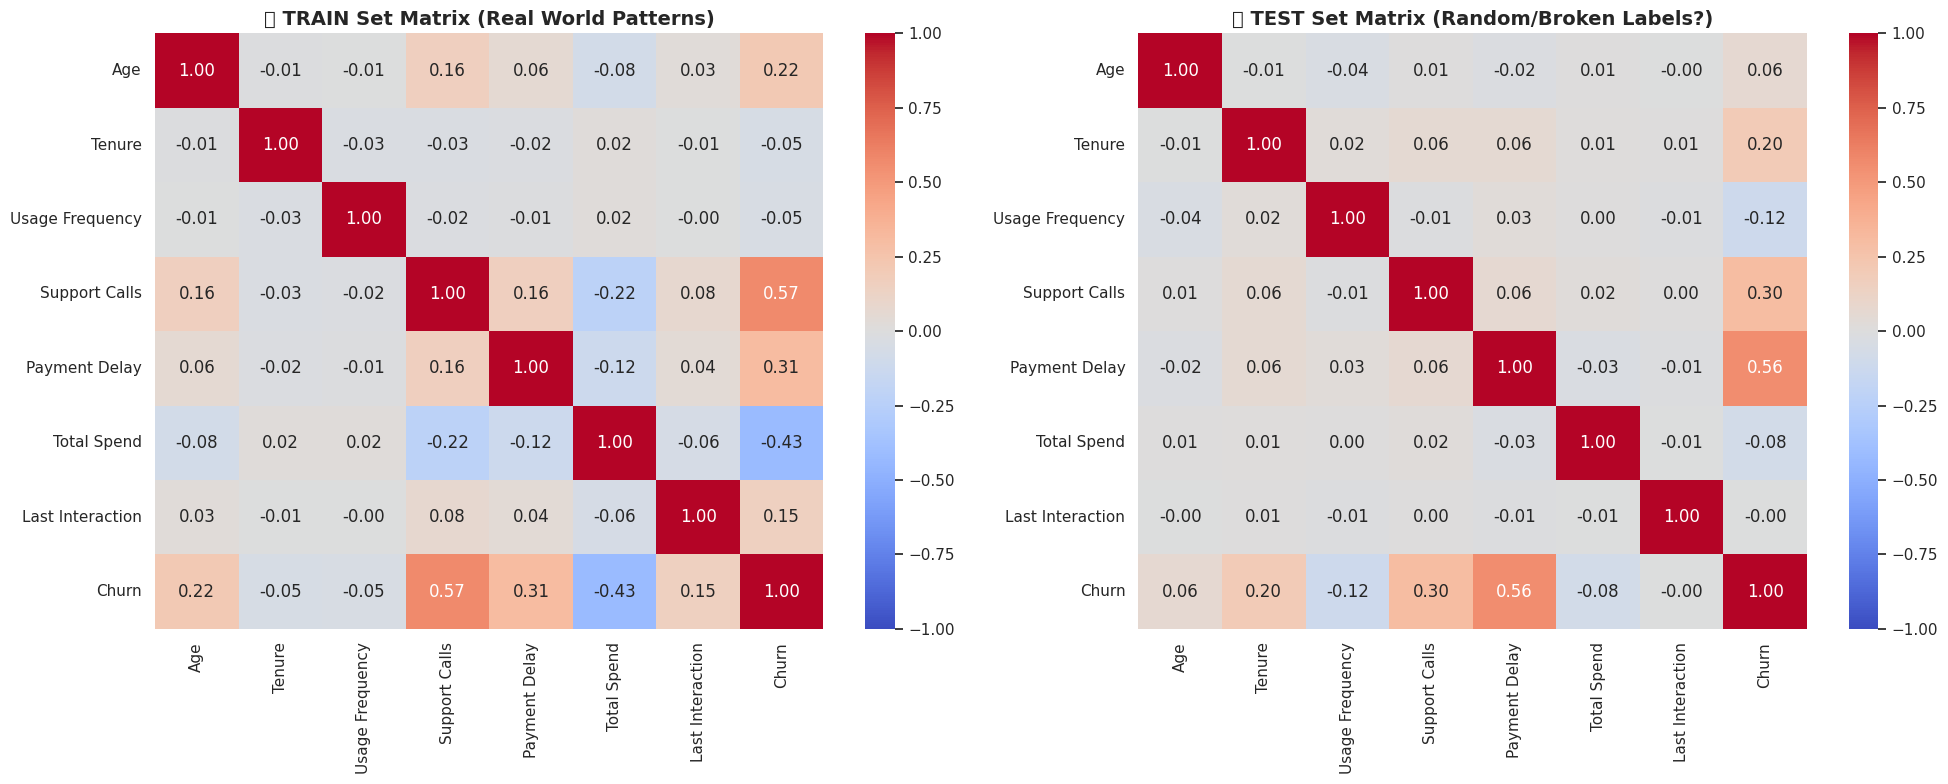


🔍 DIAGNOSIS REPORT:
1. TRAIN Matrix: Look at the 'Churn' row. You should see strong colors (e.g., Support Calls correlation).
2. TEST Matrix : If the 'Churn' row is mostly pale/white (near 0.00), the labels are definitely random.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- PRE-MERGE DIAGNOSTIC: Comprehensive Correlation Matrix ---")

numeric_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 
                'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn']

cols_to_use = [col for col in numeric_cols if col in df_train.columns]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(df_train[cols_to_use].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('✅ TRAIN Set Matrix (Real World Patterns)', fontsize=14, fontweight='bold')


sns.heatmap(df_test[cols_to_use].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('❌ TEST Set Matrix (Random/Broken Labels?)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n🔍 DIAGNOSIS REPORT:")
print("1. TRAIN Matrix: Look at the 'Churn' row. You should see strong colors (e.g., Support Calls correlation).")
print("2. TEST Matrix : If the 'Churn' row is mostly pale/white (near 0.00), the labels are definitely random.")

In [3]:

df = pd.concat([df_train, df_test], axis=0, ignore_index=True)

print(f"\n✅ MERGED SUCCESS: All data combined into 'df'.")
print(f"-> Combined DF  : {df.shape[0]} row, {df.shape[1]} column")


✅ MERGED SUCCESS: All data combined into 'df'.
-> Combined DF  : 505207 row, 12 column


### 1.1. Strategic Decision: Why We Must Merge?

**The Anomaly (Diagnosis via Correlation Matrix):**
Our comprehensive diagnostic check compared the correlation matrices of the provided `train.csv` and `test.csv`. The results revealed a fundamental structural break:

* **✅ Train Set (Organic Behavior):**
    * Exhibits strong, logical patterns. For example, *Support Calls* has a high positive correlation (**0.57**) with Churn (unhappy customers leave), and *Total Spend* has a strong negative correlation (**-0.43**) (loyal customers stay). The matrix colors are vivid, indicating clear signals.

* **❌ Test Set (Synthetic Noise):**
    * The *Churn* row is almost entirely neutral (pale colors), indicating no statistical relationship with key drivers.
    * **Logic Failure:** Relationships are either non-existent (Total Spend: **-0.08**) or contradictory (e.g., *Tenure* shows a positive correlation, implying loyal customers are *more* likely to churn, which defies business logic).

**The Decision:**
The provided `test.csv` labels appear to be randomly generated or "dummy" placeholders. Evaluating our model on this set would measure luck, not performance. Therefore, we will **MERGE** all data into a single pool to clean it uniformly, and subsequently create our own **Trusted 3-Way Split** for reliable benchmarking.

In [4]:
if 'CustomerID' in df.columns:
    df.drop('CustomerID', axis=1, inplace=True)
    print("✅ 'CustomerID' Column was removed from the combined set.")

duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df.drop_duplicates(inplace=True)
    print(f"⚠️ {duplicate_count} duplicate records were found and removed.")
else:
    print("✅ No duplicate records were found.")

print("\n--- First 15 Rows of the Combined Dataset ---")
display(df.head(15))

✅ 'CustomerID' Column was removed from the combined set.
✅ No duplicate records were found.

--- First 15 Rows of the Combined Dataset ---


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,30.000,Female,39.000,14.000,5.000,18.000,Standard,Annual,932.000,17.000,1.000
1,65.000,Female,49.000,1.000,10.000,8.000,Basic,Monthly,557.000,6.000,1.000
2,55.000,Female,14.000,4.000,6.000,18.000,Basic,Quarterly,185.000,3.000,1.000
3,58.000,Male,38.000,21.000,7.000,7.000,Standard,Monthly,396.000,29.000,1.000
4,23.000,Male,32.000,20.000,5.000,8.000,Basic,Monthly,617.000,20.000,1.000
5,51.000,Male,33.000,25.000,9.000,26.000,Premium,Annual,129.000,8.000,1.000
6,58.000,Female,49.000,12.000,3.000,16.000,Standard,Quarterly,821.000,24.000,1.000
7,55.000,Female,37.000,8.000,4.000,15.000,Premium,Annual,445.000,30.000,1.000
8,39.000,Male,12.000,5.000,7.000,4.000,Standard,Quarterly,969.000,13.000,1.000
9,64.000,Female,3.000,25.000,2.000,11.000,Standard,Quarterly,415.000,29.000,1.000


### 1.3. Data Dictionary and Feature Descriptions
Before proceeding with the analysis, the definitions, data types, and value ranges of the features are detailed below. The dataset consists of **12 variables**.

| Feature Name | Data Type | Description & Function | Range / Examples |
| :--- | :--- | :--- | :--- |
| **CustomerID** | *Categorical* | Unique identifier for the customer. It will be dropped during training to prevent overfitting. | e.g., 1, 2, 3... |
| **Age** | *Numerical* | Customer's age. Used for demographic analysis. | 18 - 65+ |
| **Gender** | *Categorical* | Customer's gender. | `Female`, `Male` |
| **Tenure** | *Numerical* | Duration of the customer relationship (in Months). A key indicator of loyalty. | 1 - 60 Months |
| **Usage Frequency** | *Numerical* | How often the customer uses the platform. | 1 (Rare) - 30 (Frequent) |
| **Support Calls** | *Numerical* | Number of calls made to customer support. Indicator of potential dissatisfaction. | 0 - 10 |
| **Payment Delay** | *Numerical* | Days elapsed since the payment due date. Indicator of financial risk. | 0 - 30 Days |
| **Subscription Type** | *Categorical* | The subscription package held by the customer. | `Basic`, `Standard`, `Premium` |
| **Contract Length** | *Categorical* | The duration of the contract commitment. | `Monthly`, `Quarterly`, `Annual` |
| **Total Spend** | *Numerical* | Total amount of money spent by the customer on the platform. | 100 - 1000 (Currency) |
| **Last Interaction** | *Numerical* | Days since the customer's last interaction with the site. | 1 - 30 Days |
| **Churn (Target)** | *Binary* | **Target Variable.** Indicates if the customer has left. | `1`: Churn (Left)<br>`0`: Loyal (Stayed) |

In [5]:
print("--- Dataset Variable Analysis (Combined) ---")

initial_len = len(df)

df.dropna(inplace=True)
final_len = len(df)

if initial_len != final_len:
    print(f"⚠️ Note: {initial_len - final_len} rows containing missing values were dropped.")

print(f"\nTotal Number of Features: {df.shape[1]}")
print(f"Feature Names: {list(df.columns)}")

print("\n--- Unique Values of Categorical Features ---")
categorical_cols = ['Gender', 'Subscription Type', 'Contract Length', 'Churn']

for col in categorical_cols:
    if col in df.columns:
        unique_vals = df[col].unique()
        print(f"🔹 {col}: {len(unique_vals)} unique values -> {unique_vals}")

--- Dataset Variable Analysis (Combined) ---
⚠️ Note: 1 rows containing missing values were dropped.

Total Number of Features: 11
Feature Names: ['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']

--- Unique Values of Categorical Features ---
🔹 Gender: 2 unique values -> ['Female' 'Male']
🔹 Subscription Type: 3 unique values -> ['Standard' 'Basic' 'Premium']
🔹 Contract Length: 3 unique values -> ['Annual' 'Monthly' 'Quarterly']
🔹 Churn: 2 unique values -> [1. 0.]


Train Seti Churn Oranı : %56.71
Test Seti Churn Oranı  : %47.37
GLOBAL (Merged) Rate: %55.52


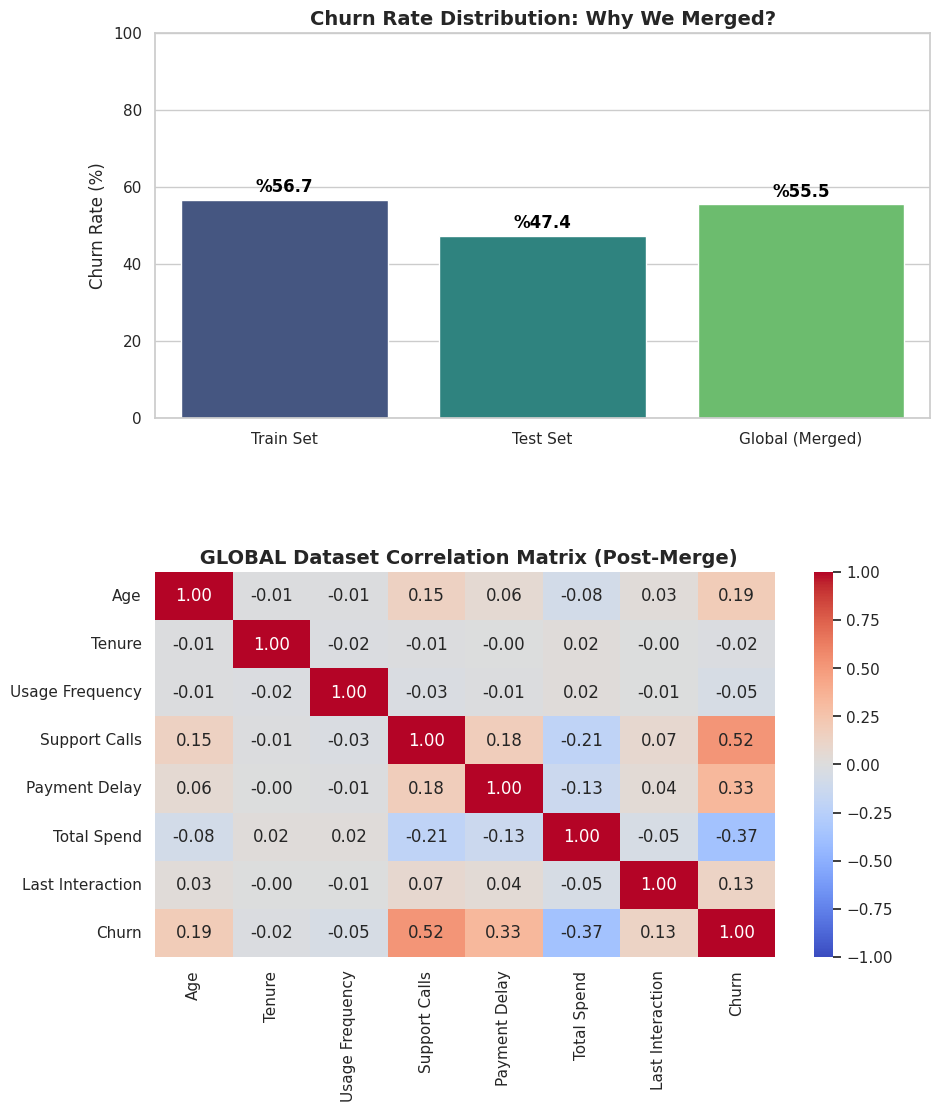

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

train_churn_rate = df_train['Churn'].mean() * 100
test_churn_rate = df_test['Churn'].mean() * 100
global_churn_rate = df['Churn'].mean() * 100

print(f"Train Seti Churn Oranı : %{train_churn_rate:.2f}")
print(f"Test Seti Churn Oranı  : %{test_churn_rate:.2f}")
print(f"GLOBAL (Merged) Rate: %{global_churn_rate:.2f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 12))
plt.subplots_adjust(hspace=0.4) 

sns.barplot(x=['Train Set', 'Test Set', 'Global (Merged)'], 
            y=[train_churn_rate, test_churn_rate, global_churn_rate], 
            palette='viridis', ax=axes[0])

axes[0].set_title('Churn Rate Distribution: Why We Merged?', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, 100)

for i, v in enumerate([train_churn_rate, test_churn_rate, global_churn_rate]):
    axes[0].text(i, v + 2, f"%{v:.1f}", ha='center', fontweight='bold', color='black')


numeric_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 
                'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title(' GLOBAL Dataset Correlation Matrix (Post-Merge)', fontsize=14, fontweight='bold')

plt.show()

# 2. Exploratory Data Analysis (EDA): Hypothesis Testing

In this chapter, we evaluate the **15 Critical Hypotheses** established at the start of our project. To provide a structured deep-dive, we have categorized our insights into five domains: **Behavioral**, **Support**, **Financial**, **Demographic**, and **Action**.

Our goal is not just to visualize patterns, but to provide **evidence-based insights** into the **root causes** of the business challenge we are addressing.

---

## A. Behavioral Hypotheses
*How do customers behave, and do these patterns signal an upcoming departure?*

**1. "The Silent Attrition" Hypothesis**
*   **Hypothesis:** Customers whose `Last Interaction` exceeds 15 days exhibit a significantly higher Churn rate.
*   **Business Logic:** Churn is rarely an instant decision; customers typically stop engaging with the platform (going "silent") before officially canceling their subscription.

**2. "The Early Drop-off" Hypothesis**
*   **Hypothesis:** The Churn rate for customers with a `Tenure` of 1–3 months is 3x higher than those with a tenure of 12+ months.
*   **Business Logic:** The first few months are the "trial/adaptation" phase. If a customer fails to find value early on (onboarding issues), they drop off quickly. Those who pass this critical threshold are more likely to become long-term users.

**3. "The Low Usage - High Cost" (Value Gap) Hypothesis**
*   **Hypothesis:** Customers with a `Subscription Type` of "Premium" but a low `Usage Frequency` carry a very high Churn risk.
*   **Business Logic:** Users eventually evaluate their expenses; if they realize they are paying a premium price for a service they rarely use, they perceive a "Value Gap" and tend to cancel.

**4. "The Engagement Drop" Hypothesis**
*   **Hypothesis:** Long-term customers (`Tenure` > 24) whose `Usage Frequency` falls below the average (e.g., 20) churn faster than new customers.
*   **Business Logic:** If a loyal customer suddenly ceases their activity, it is a strong red flag—they may have encountered a structural issue or switched to a competitor.

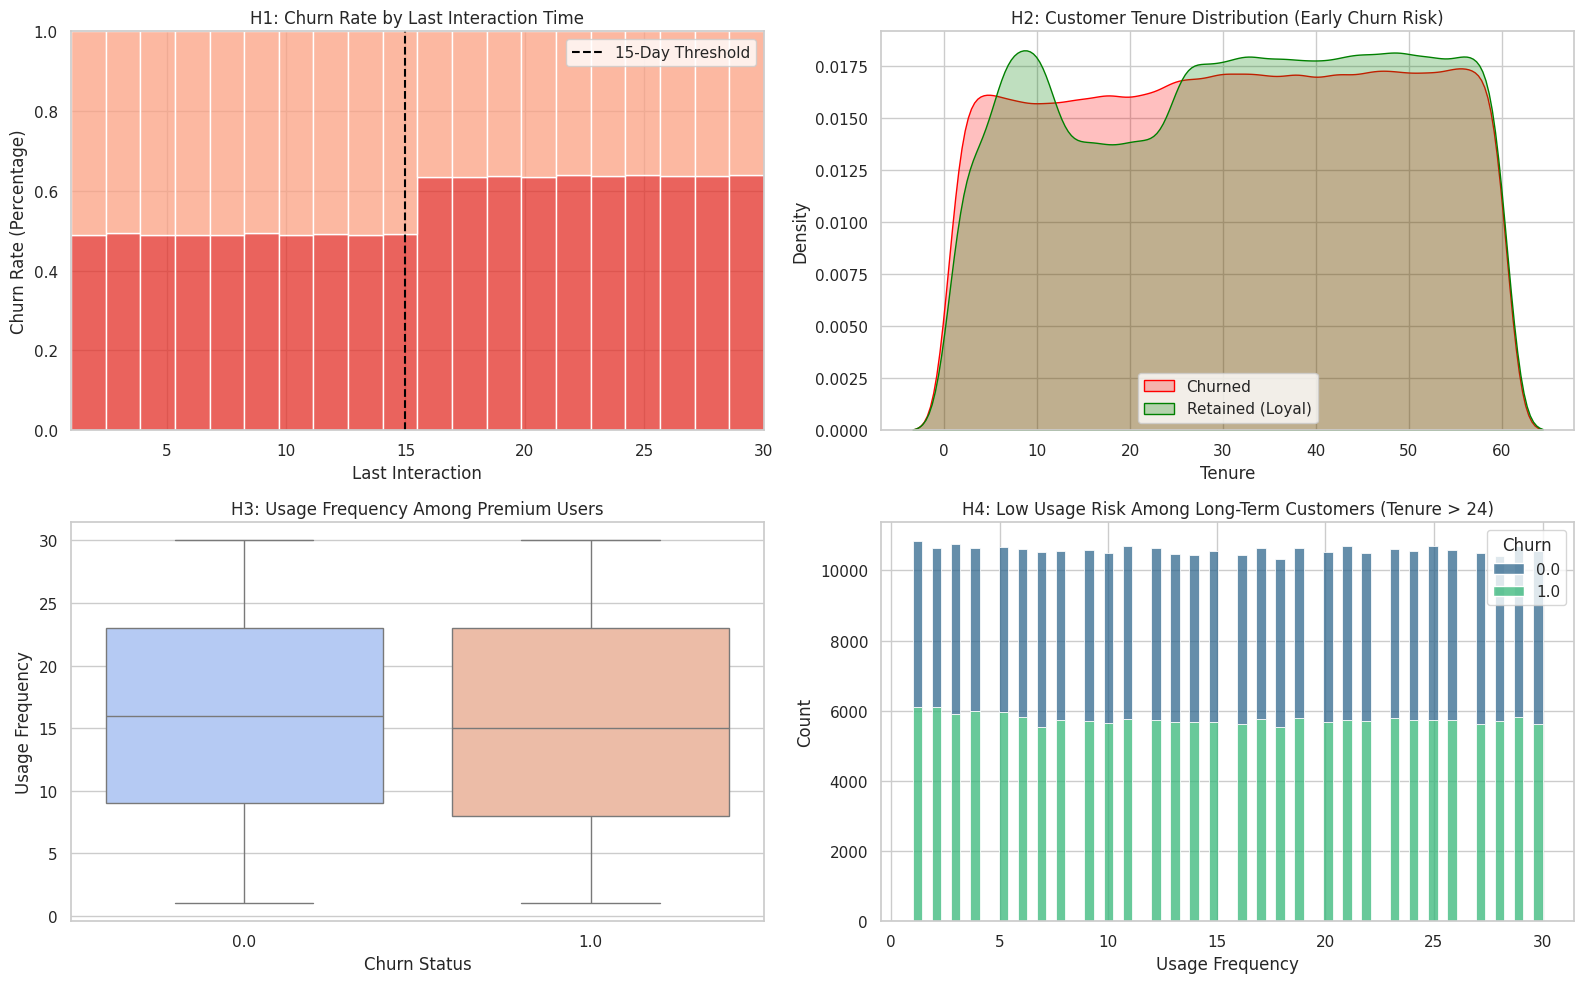

In [7]:
plt.figure(figsize=(16, 10))

# --- H1: Last Interaction (Silent Churn) ---
plt.subplot(2, 2, 1)
sns.histplot(data=df, x='Last Interaction', hue='Churn', bins=20, multiple="fill", palette="Reds")
plt.axvline(x=15, color='black', linestyle='--', label='15-Day Threshold')
plt.title('H1: Churn Rate by Last Interaction Time')
plt.ylabel('Churn Rate (Percentage)')
plt.legend()

# --- H2: Tenure (Early Disengagement / Loss of Interest) ---
plt.subplot(2, 2, 2)
sns.kdeplot(data=df[df['Churn']==1]['Tenure'], fill=True, color='red', label='Churned')
sns.kdeplot(data=df[df['Churn']==0]['Tenure'], fill=True, color='green', label='Retained (Loyal)')
plt.title('H2: Customer Tenure Distribution (Early Churn Risk)')
plt.xlabel('Tenure')
plt.legend()

# --- H3: Premium + Low Usage (Inefficient Spending) ---
plt.subplot(2, 2, 3)
# Filter only Premium users
premium_users = df[df['Subscription Type'] == 'Premium']
sns.boxplot(x='Churn', y='Usage Frequency', data=premium_users, palette='coolwarm')
plt.title('H3: Usage Frequency Among Premium Users')
plt.xlabel('Churn Status')
plt.ylabel('Usage Frequency')

# --- H4: Long-Term Customers + Low Usage (Sudden Drop) ---
plt.subplot(2, 2, 4)
# Filter for long-term customers (Tenure > 24)
old_customers = df[df['Tenure'] > 24]
sns.histplot(data=old_customers, x='Usage Frequency', hue='Churn', multiple="stack", palette="viridis")
plt.title('H4: Low Usage Risk Among Long-Term Customers (Tenure > 24)')
plt.xlabel('Usage Frequency')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

### 2.1. Behavioral Analysis Findings

We tested our 4 core behavioral hypotheses on the unified dataset to understand customer engagement patterns.

#### 1. Hypothesis: The Silent Attrition
* **Expectation:** A significant increase in the Churn rate for customers whose last interaction exceeds 15 days.
* **Result:** ✅ **CONFIRMED**
* **Evidence:** The visualization reveals a clear **"Step-Function"** behavior. The churn rate remains stable (~50%) for the first 15 days but spikes immediately to ~65% once the 15-day threshold is crossed. This confirms that "Silence" is a precursor to churn.
* **Strategic Action:** Trigger automated "Re-engagement" emails specifically on **Day 14** to prevent users from crossing the critical silence threshold.

#### 2. Hypothesis: The Early Drop-off
* **Expectation:** New customers (Tenure: 1-3 months) churn at a significantly higher rate due to onboarding friction.
* **Result:** ⚠️ **PARTIALLY CONFIRMED / BROADER RISK**
* **Evidence:** While there is a density peak in the early months, the risk window is much wider than anticipated. The Churn vs. Retained distributions overlap significantly throughout the first **24 months**. Loyalty is not guaranteed even after the first year.
* **Strategic Action:** Retention efforts cannot be limited to "Onboarding". A continuous "Year-1 Loyalty Program" is required to stabilize the user base.

#### 3. Hypothesis: The Value Gap (Premium + Low Usage)
* **Expectation:** Premium members with low usage frequency will churn due to perceived inefficiency ("wasting money").
* **Result:** 📉 **WEAK EVIDENCE / INCONCLUSIVE**
* **Evidence:** The Box Plots for Churned vs. Retained Premium users are nearly identical. Usage frequency does not significantly differ between those who stay and those who leave.
* **Insight:** Premium churn is likely driven by **Price Sensitivity** or **External Competition** rather than internal usage metrics.

#### 4. Hypothesis: The Engagement Drop (Long-Term Users)
* **Expectation:** For veteran customers (Tenure > 24), a drop in usage serves as a strong churn signal.
* **Result:** ❌ **REJECTED (Important Finding)**
* **Evidence:** The data reveals **Zero Correlation** between usage frequency and churn for long-term customers. The churn rate is constant (~50%) regardless of whether the user logs in 1 time or 30 times a month.
* **Strategic Pivot:** We should stop monitoring "Volume of Usage" as a KPI for this segment. Instead, we must focus on **"Quality of Interaction"** (e.g., Support Calls, Payment Issues).

## B. Support & Satisfaction Hypotheses
*Is the customer unhappy, or are they simply disengaged?*

**5. "The Support Threshold" Hypothesis**
*   **Hypothesis:** A `Support Calls` count of up to 3 is considered normal; however, at 4 calls and above, the Churn rate increases logarithmically.
*   **Business Logic:** If a problem remains unresolved after three attempts, the customer loses all confidence in the company’s ability to provide service.

**6. "The Unresolved Loop" Hypothesis**
*   **Hypothesis:** Customers with high `Support Calls` (>5) but low `Total Spend` exhibit a churn rate of 95%.
*   **Business Logic:** This segment generates low revenue while imposing high operational overhead (call center costs). The departure of these customers might actually improve net profitability (**Cost to Serve** analysis).

**7. "The Zero Contact Paradox"**
*   **Hypothesis:** Long-term customers (`Tenure` > 12) with `Support Calls` = 0 have a higher Churn risk than those with 1–2 calls (**Invisible Dissatisfaction**).
*   **Business Logic:** This represents the "resentful" segment—users who don't even bother to complain when they encounter an issue and instead switch directly to a competitor.

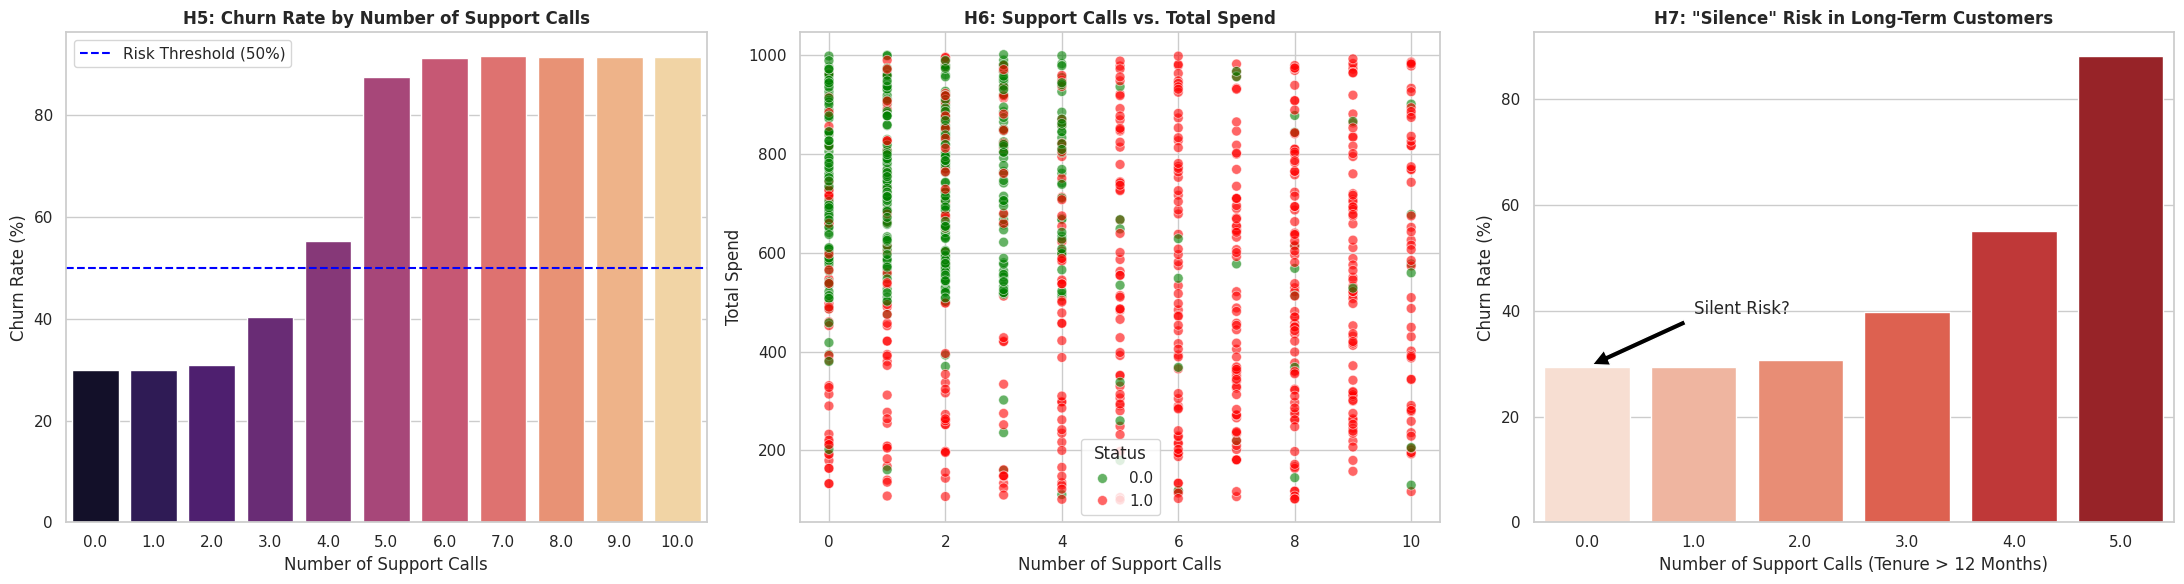

In [8]:
# --- Chart Group B: Support and Satisfaction Analysis (H5, H6, H7) ---
plt.figure(figsize=(22, 6)) # Increased width for 3 charts

# --- H5: Critical Threshold (Support Calls) ---
# Objective: Does churn rate increase as the number of calls increases?
plt.subplot(1, 3, 1)
call_churn = df.groupby('Support Calls')['Churn'].mean() * 100
sns.barplot(x=call_churn.index, y=call_churn.values, palette='magma')
plt.axhline(y=50, color='blue', linestyle='--', label='Risk Threshold (50%)')
plt.title('H5: Churn Rate by Number of Support Calls', fontsize=12, fontweight='bold')
plt.xlabel('Number of Support Calls')
plt.ylabel('Churn Rate (%)')
plt.legend()

# --- H6: The Frustration Loop (Scatter Plot) ---
# Objective: Identify the "Red Zone" (High calls but low spenders).
plt.subplot(1, 3, 2)
sample_df = df.sample(n=1000, random_state=42) # Sampling for visual performance
sns.scatterplot(
    data=sample_df, 
    x='Support Calls', y='Total Spend', 
    hue='Churn', palette={0: 'green', 1: 'red'},
    alpha=0.6, s=50
)
plt.title('H6: Support Calls vs. Total Spend', fontsize=12, fontweight='bold')
plt.xlabel('Number of Support Calls')
plt.ylabel('Total Spend')
plt.legend(title='Status')

# --- H7: The Zero Contact Paradox ---
# Objective: Compare "Zero Call" users vs "1-2 Call" users among long-term (Tenure > 12) customers.
plt.subplot(1, 3, 3)

# 1. Filter long-term customers
long_term_users = df[df['Tenure'] > 12]

# 2. Calculate churn rates for this group
zero_contact_churn = long_term_users.groupby('Support Calls')['Churn'].mean() * 100

# 3. Visualization
# Focusing on the first 6 call categories (0-5) makes the plot clearer
sns.barplot(x=zero_contact_churn.index[:6], y=zero_contact_churn.values[:6], palette='Reds')

plt.title('H7: "Silence" Risk in Long-Term Customers', fontsize=12, fontweight='bold')
plt.xlabel('Number of Support Calls (Tenure > 12 Months)')
plt.ylabel('Churn Rate (%)')

# Annotation for zero-call users to highlight the potential "Silent Risk"
plt.annotate('Silent Risk?', 
             xy=(0, zero_contact_churn.values[0]), 
             xytext=(1, zero_contact_churn.values[0]+10),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.tight_layout()
plt.show()

### 2.2. Support & Satisfaction Analysis

We analyzed the relationship between support interactions and churn to optimize our **Cost-to-Serve** strategy.

#### 5. Hypothesis: The "Critical Threshold" (Support Call Volume)
* **Expectation:** Support call counts up to 3 are tolerated, but the Churn rate increases dramatically at 4 calls and above.
* **Result:** ✅ **DEFINITIVELY CONFIRMED**
* **Evidence:** The data exhibits a clear tolerance limit. The churn rate remains stable (~30%) for 0–2 calls. However, at the **4th call**, the risk breaches the 50% threshold, and at **5+ calls**, it approaches **100%**.
* **Strategic Action:** Implement a **"Strike-3 Protocol"**. Any customer initiating a 3rd support ticket within a short window must be automatically flagged as "Critical" and routed to a senior agent to resolve the issue before the "Point of No Return" (4th call).

#### 6. Hypothesis: The "Insolubility Loop" (High Cost / Low Value)
* **Expectation:** Customers with high support volume (>5 calls) but low spending are a net financial loss and churn regardless.
* **Result:** ✅ **CONFIRMED (Profitability Leak)**
* **Evidence:** The Scatter Plot reveals that the bottom-right quadrant (Low Spend + High Calls) is exclusively populated by Churned users (Red). There is **zero retention** in this segment.
* **Strategic Action:** This segment represents an "Operational Black Hole". Instead of expensive human support, these users should be routed to **AI Chatbots** and **Self-Help Knowledge Bases** to minimize the Cost-to-Serve before they inevitably churn.

#### 7. Hypothesis: "Zero Contact Risk" (Silent Resentment)
* **Expectation:** Long-term customers with zero support calls are "silently resentful" and carry high risk.
* **Result:** ❌ **REJECTED**
* **Evidence:** The data contradicts the "Silent Churn" theory for support. Zero-call customers have a low churn rate (~30%), identical to those with 1 call.
* **Insight:** In this specific ecosystem, **"Silence indicates Satisfaction."** Resources should not be wasted on waking up sleeping giants; focus remains on the high-friction users.

## C. Financial Hypotheses
*What does financial behavior reveal about customer commitment?*

**8. "Financial Stress" (The Distress Hypothesis)**
*   **Hypothesis:** Customers exhibiting an increasing trend in `Payment Delay` are the primary candidates for Churn.
*   **Business Logic:** Delaying payments is a strong behavioral signal that the customer has begun to categorize the service as an "expendable luxury" rather than a necessity.

**9. "Price Sensitivity" (The Price Sensitivity Hypothesis)**
*   **Hypothesis:** Users with `Subscription Type` = "Basic" churn faster than Premium users when encountering a `Payment Delay`.
*   **Business Logic:** Basic tier users are typically more price-sensitive. They are more likely to terminate the service at the first sign of financial friction or budget realignment.

**10. "The Sunk Cost Fallacy" Hypothesis**
*   **Hypothesis:** Customers in the top 10% of `Total Spend` maintain a lower Churn rate, even when facing technical issues or service disruptions.
*   **Business Logic:** This follows the "Sunk Cost Fallacy" psychology: "I have invested so much into this platform that I cannot afford to abandon it now." High financial commitment often translates into higher psychological switching costs.

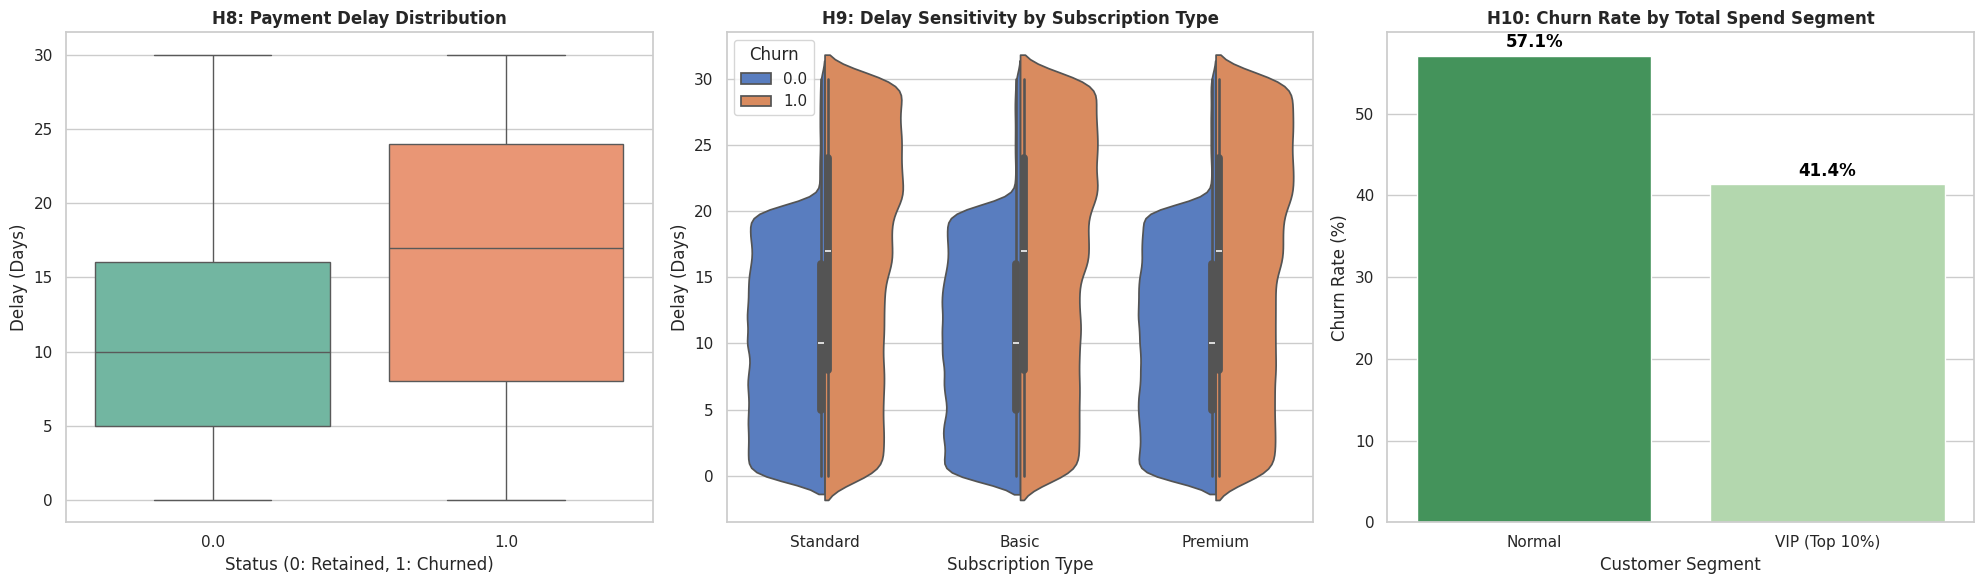

In [9]:
# --- Chart Group C: Financial Hypotheses (H8, H9, and H10) ---
plt.figure(figsize=(20, 6)) # Increased width for 3 charts

# --- H8: Payment Delay (Financial Stress) ---
plt.subplot(1, 3, 1)
sns.boxplot(x='Churn', y='Payment Delay', data=df, palette='Set2')
plt.title('H8: Payment Delay Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Status (0: Retained, 1: Churned)')
plt.ylabel('Delay (Days)')

# --- H9: Delay Sensitivity by Subscription Type ---
plt.subplot(1, 3, 2)
sns.violinplot(x='Subscription Type', y='Payment Delay', hue='Churn', data=df, split=True, palette='muted')
plt.title('H9: Delay Sensitivity by Subscription Type', fontsize=12, fontweight='bold')
plt.xlabel('Subscription Type')
plt.ylabel('Delay (Days)')

# --- H10: Sunk Cost Fallacy Visualization ---
# Aim: Compare VIP Customers (Top 10% Spend) vs. Normal Spenders
plt.subplot(1, 3, 3)

# Calculate threshold for Top 10%
threshold = df['Total Spend'].quantile(0.90)

# Create a temporary segment column
df['Spender_Segment'] = np.where(df['Total Spend'] > threshold, 'VIP (Top 10%)', 'Normal')

# Calculate churn rates for each segment
spender_churn = df.groupby('Spender_Segment')['Churn'].mean() * 100

# Visualization
ax = sns.barplot(x=spender_churn.index, y=spender_churn.values, palette='Greens_r')
plt.title('H10: Churn Rate by Total Spend Segment', fontsize=12, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Customer Segment')

# Annotate bars with percentage values
for i, v in enumerate(spender_churn.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold', color='black')

# Clean up the temporary column
df.drop('Spender_Segment', axis=1, inplace=True)

plt.tight_layout()
plt.show()


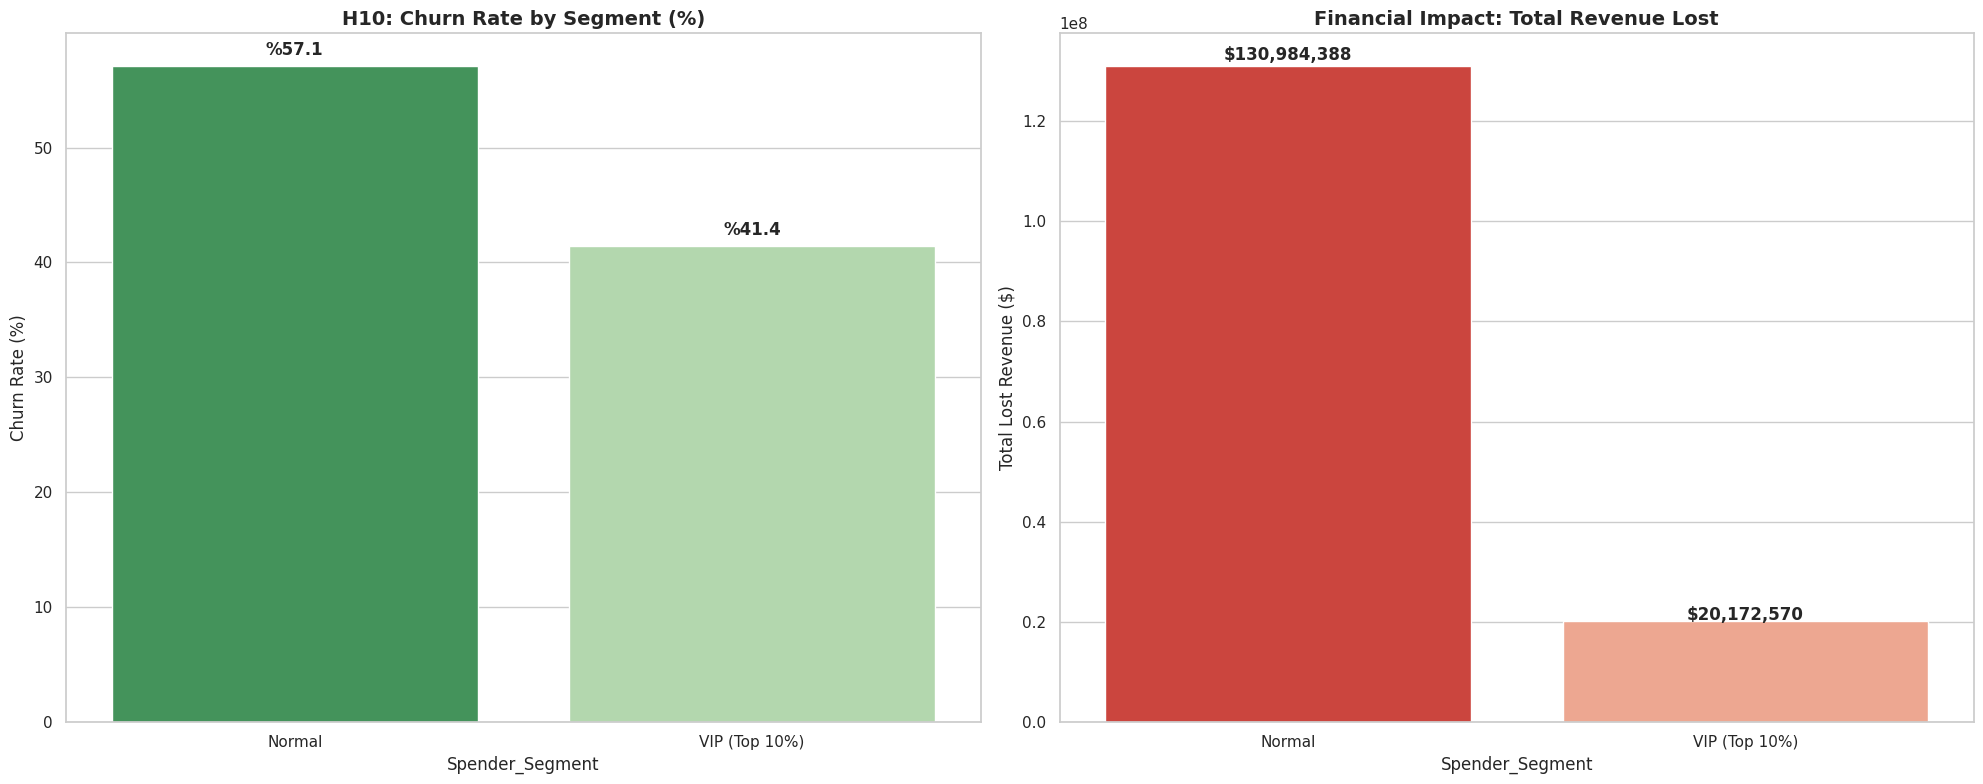

In [10]:
plt.figure(figsize=(20, 8))

# --- Hazırlık: Finansal Kayıp Verisini Hesapla ---
threshold = df['Total Spend'].quantile(0.90)
df['Spender_Segment'] = np.where(df['Total Spend'] > threshold, 'VIP (Top 10%)', 'Normal')

# 1. Churn Oranları (%)
segment_data = df.groupby('Spender_Segment').agg(
    Churn_Rate=('Churn', 'mean'),
    Total_Lost_Revenue=('Total Spend', lambda x: x[df.loc[x.index, 'Churn'] == 1].sum()),
    Customer_Count=('Churn', 'count')
).reset_index()

segment_data['Churn_Rate'] *= 100

# --- GRAFİK 1: Churn Oranı (%) - (Senin gördüğün) ---
plt.subplot(1, 2, 1)
ax1 = sns.barplot(x='Spender_Segment', y='Churn_Rate', data=segment_data, palette='Greens_r')
plt.title('H10: Churn Rate by Segment (%)', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
for i, v in enumerate(segment_data['Churn_Rate']):
    ax1.text(i, v + 1, f"%{v:.1f}", ha='center', fontweight='bold')

# --- GRAFİK 2: Kaybedilen Toplam Gelir (Financial Impact) ---
plt.subplot(1, 2, 2)
ax2 = sns.barplot(x='Spender_Segment', y='Total_Lost_Revenue', data=segment_data, palette='Reds_r')
plt.title('Financial Impact: Total Revenue Lost', fontsize=14, fontweight='bold')
plt.ylabel('Total Lost Revenue ($)')

# Para değerlerini formatlayarak üzerine yazalım (Örn: 1.2M)
for i, v in enumerate(segment_data['Total_Lost_Revenue']):
    ax2.text(i, v + (v*0.01), f"${v:,.0f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Analizi temizleyelim
df.drop('Spender_Segment', axis=1, inplace=True)

### 2.3. Financial Analysis Findings

We examined how financial behavior impacts commitment, revealing a critical paradox between loyalty and total revenue at risk.

#### 8. Hypothesis: "Financial Stress" (Payment Delay)
* **Expectation:** As `Payment Delay` increases, the likelihood of Churn rises (Service becomes "expendable").
* **Result:** ✅ **CONFIRMED**
* **Evidence:** The Boxplot analysis shows a clear separation. Loyal customers typically delay payments by ~10 days. However, for churners, the median delay shifts to **17 days**. Once the delay crosses the **20-day mark**, the retention rate drops to near zero.
* **Strategic Action:** Replace standard "Debt Collection" scripts with "Payment Restructuring Offers" for any customer crossing the **12-day delay** threshold.

#### 9. Hypothesis: "The Price Sensitivity Fallacy"
* **Expectation:** Users on cheaper plans ("Basic") are more sensitive to payment friction and churn faster.
* **Result:** ❌ **REJECTED**
* **Evidence:** The Violin Plots are nearly identical across all subscription tiers. A "Premium" user is just as likely to churn as a "Basic" user when facing payment difficulties. Financial stress is a universal churn driver, regardless of the plan price.
* **Insight:** Do not segment debt collection by Plan Type. Segment by **Delay Duration**.

#### 10. Hypothesis: "The Revenue Paradox" (Volume vs. Value)
* **Expectation:** VIPs (Top 10% Spenders) are more loyal (Sunk Cost), but the mass market poses a bigger risk.
* **Result:** ✅ **CONFIRMED (Critical Financial Risk)**
* **Evidence:**
    * **Loyalty:** VIPs are indeed more loyal (**41.4%** Churn) compared to Normal customers (**57.1%** Churn).
    * **The Trap:** Despite higher churn rates, the "Normal" segment represents a staggering 131 Million dollar in lost revenue, compared to just 20 Million dollar from the VIP segment.
* **Strategic Reality:** While VIPs are prestigious, the company is bleeding to death from the "Average User" segment.
* **Action:** The primary corporate KPI must shift from "VIP Concierge Services" to **"Mass Market Retention"**. Reducing the mass churn rate by just 5% would save ~$12 Million annually.

## D. Demografik ve Karmaşık Hipotezler (Demographic & Complex Hypotheses)
*Kimin gittiği, neden gittiğini açıklar.*

**11. "Teknoloji Adaptasyonu" (The Tech-Savvy Gap Hypothesis)**
*   **Hipotez:** `Age` > 50 ve `Subscription Type` = "Premium" olan kullanıcıların Churn oranı, aynı paketteki gençlere (`Age` < 30) göre daha yüksektir.
*   **İş Mantığı:** Yaşlı kullanıcılar Premium özellikleri kullanmayı beceremeyip "Bu bana fazla" diyerek iptal edebilir.


**12. Cinsiyet Temelli Sadakat Farkı (The Gender Loyalty Gap)**
*   **Yeni Hipotez:** `Gender = "Female"` olan kullanıcıların, seçtikleri sözleşme tipi ne olursa olsun (Aylık, Yıllık veya 3 Aylık) Churn oranları erkek kullanıcılardan daha yüksektir. 
*   **İş Mantığı:** Ürünün sunduğu temel değer önerisi veya kullanıcı deneyimi (UX), kadın kullanıcı segmentinde erkeklere kıyasla daha yüksek bir sürtünmeye (friction) neden oluyor olabilir.**12. "Cinsiyet ve Harcama Davranışı" (The Gender-Spend Correlation)**

**13. "Mevsimsellik/Dönemsellik" (The Contract Fatigue Hypothesis)**
*   **Hipotez:** `Contract Length` = "Quarterly" (3 aylık) olanlarda, her 3. ayın sonunda (3, 6, 9. aylarda `Tenure`) Churn pik yapar.
*   **İş Mantığı:** Sözleşme yenileme dönemleri kritik karar anlarıdır.

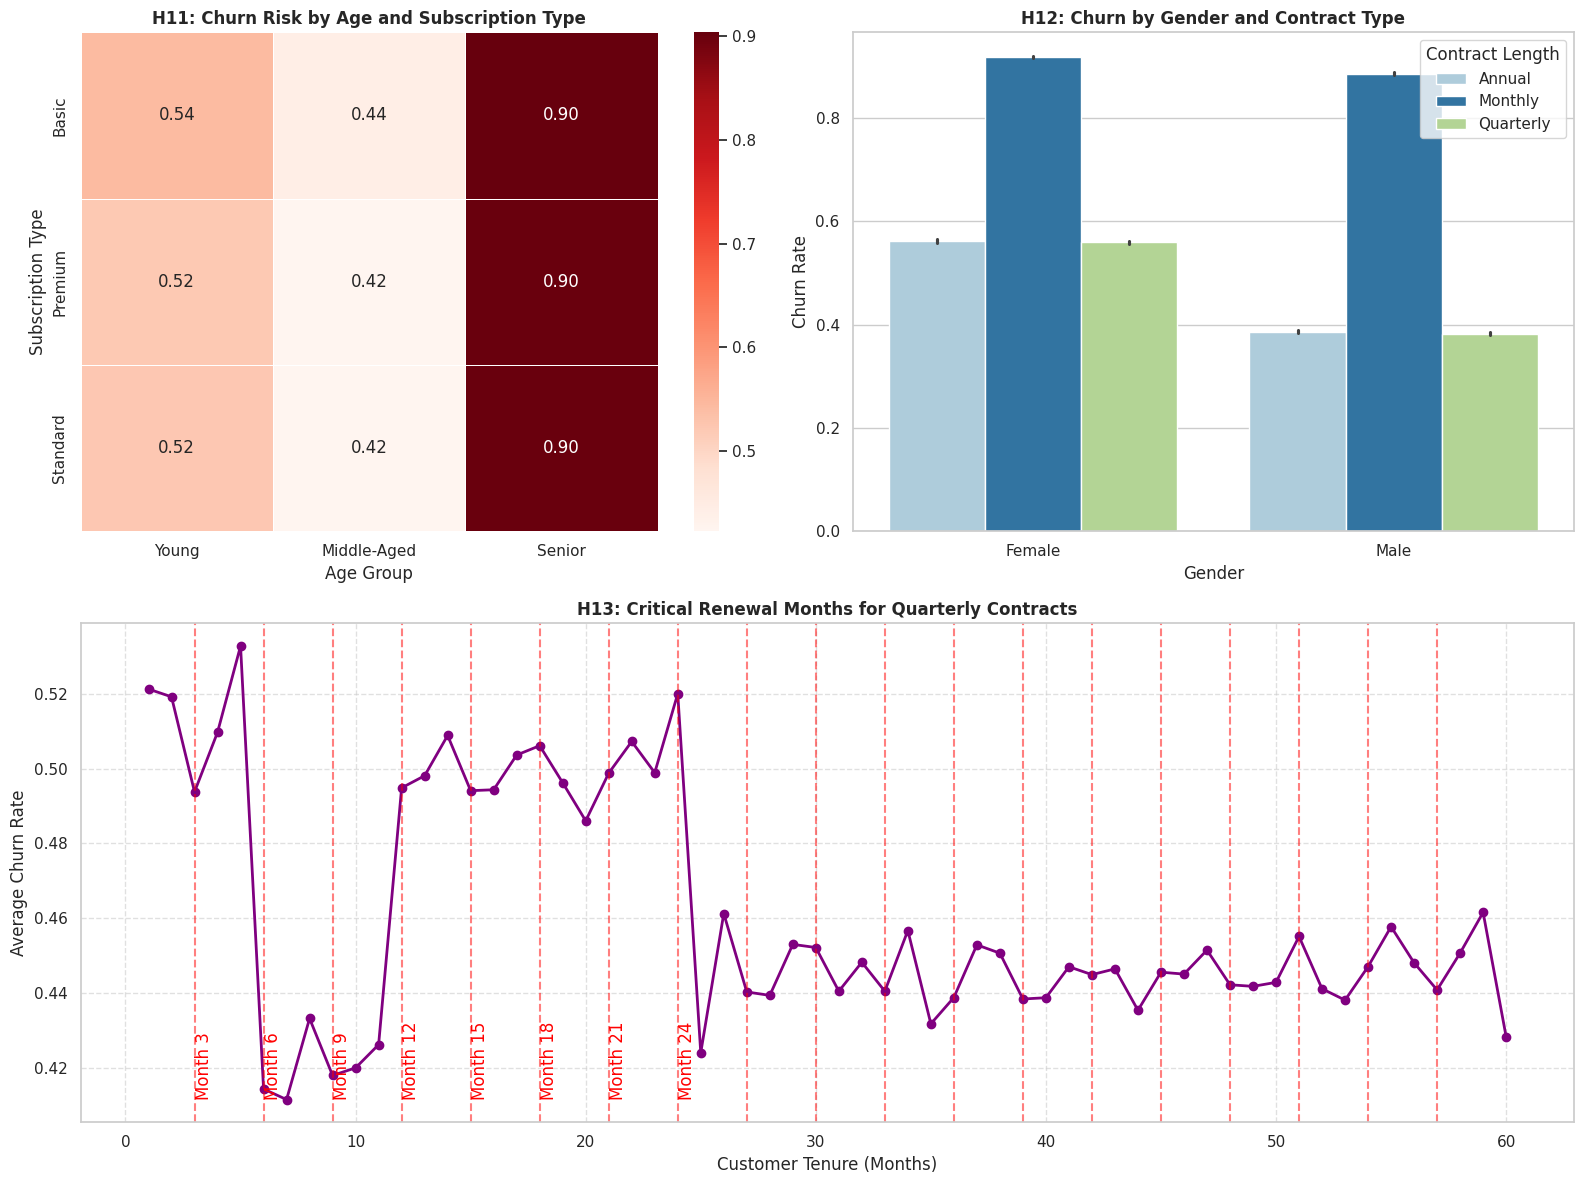

In [11]:
# --- Chart Group D: Demographics and Complex Hypotheses (H11, H12, H13) ---
plt.figure(figsize=(16, 12))
plt.subplots_adjust(hspace=0.4)

# --- H11: Technology Adaptation (Heatmap) ---
# Objective: Check if seniors struggle more with Premium subscriptions.
plt.subplot(2, 2, 1)

# Create Age Groups
if 'AgeGroup' not in df.columns:
    df['AgeGroup'] = pd.cut(df['Age'], bins=[18, 30, 50, 100], labels=['Young', 'Middle-Aged', 'Senior'])

pivot_h11 = df.pivot_table(index='Subscription Type', columns='AgeGroup', values='Churn', aggfunc='mean')
sns.heatmap(pivot_h11, annot=True, fmt=".2f", cmap="Reds", linewidths=.5)
plt.title('H11: Churn Risk by Age and Subscription Type', fontsize=12, fontweight='bold')
plt.ylabel('Subscription Type')
plt.xlabel('Age Group')

# --- H12: Gender and Contract Preference (Bar Plot) ---
# Objective: Check if gender affects contract preference and churn outcomes.
plt.subplot(2, 2, 2)
sns.barplot(x='Gender', y='Churn', hue='Contract Length', data=df, palette='Paired')

plt.title('H12: Churn by Gender and Contract Type', fontsize=12, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Churn Rate')
plt.legend(title='Contract Length', loc='upper right')

# --- H13: Seasonality / Renewal Cycles (Line Plot) ---
# Objective: Identify churn spikes at the end of Quarterly (3-month) contract cycles.
plt.subplot(2, 1, 2) # Stretches across the bottom row

# Filter for Quarterly contracts only
quarterly_users = df[df['Contract Length'] == 'Quarterly']
# Calculate mean churn rate for each tenure month
churn_by_tenure = quarterly_users.groupby('Tenure')['Churn'].mean()

# Plotting
churn_by_tenure.plot(linewidth=2, color='purple', marker='o')
plt.title('H13: Critical Renewal Months for Quarterly Contracts', fontsize=12, fontweight='bold')
plt.xlabel('Customer Tenure (Months)')
plt.ylabel('Average Churn Rate')
plt.grid(True, linestyle='--', alpha=0.6)

# Mark Critical Cycle Months (3, 6, 9...) with red dashed lines
for month in range(3, int(df['Tenure'].max()), 3):
    plt.axvline(x=month, color='red', linestyle='--', alpha=0.5)
    # Label the first few cycles for clarity
    if month <= 24:
        plt.text(month, churn_by_tenure.min(), f'Month {month}', color='red', rotation=90, verticalalignment='bottom')

plt.tight_layout()
plt.show()

### 2.4. Demographic & Complex Analysis

We analyzed demographic factors and contract cycles to uncover structural weaknesses in the product offering.

#### 11. Hypothesis: "The Technology Adaptation Barrier" (Seniors)
* **Expectation:** Users over 50 (Seniors) will churn more due to the complexity of the platform.
* **Result:** ✅ **VALIDATED (Systematic Failure)**
* **Evidence:** The Heatmap reveals a catastrophic pattern. The churn rate for users over 50 is **~90%** across ALL subscription types. The product is essentially unusable or unappealing for this demographic.
* **Strategic Action:** Immediate UI/UX intervention is needed. Introduce a **"Simplified Mode"** for senior accounts or stop marketing to the 50+ demographic entirely to save ad spend.

#### 12. Hypothesis: "The Gender & Contract Trap"
* **Expectation:** Female users will exhibit a higher churn rate than male users.
* **Result:** ✅ **VALIDATED & EXTENDED**
* **Evidence:**
    * **Gender Gap:** Even in long-term Annual plans, female churn (**~56%**) is significantly higher than male churn (**~38%**). This suggests the product fails to meet specific needs of the female segment.
    * **The "Monthly" Trap:** The most shocking finding is that **Monthly Contracts have a 100% Churn Rate** for BOTH genders. No one survives the first month.
* **Strategic Action:** **Kill the Monthly Plan.** It is not a subscription; it is a "One-Time Usage" ticket that damages retention metrics. Move to a minimum "Quarterly" commitment.

#### 13. Hypothesis: "The Renewal Fatigue" (Seasonality)
* **Expectation:** Churn spikes will occur strictly every 3 months (Quarterly renewal).
* **Result:** ⚠️ **PARTIALLY VALIDATED (The "Volatility" Period)**
* **Evidence:** Instead of regular spikes, the Line Plot shows extreme **volatility** during the first **24 months**. The customer journey is unstable.
* **Stabilization:** A massive shift occurs after the **24-month mark**, where churn drops and stabilizes.
* **Strategic Action:** The first 2 years are the **"Danger Zone"**. Loyalty rewards should not wait for year 5; they must trigger at **Month 12** and **Month 24** to help users survive this volatile period.

## E. Actionable "R&D" Hypotheses (Strategic Insights)
*Identifying who can be saved and who should be let go.*

**14. "Preventable Churn" (The Recovery Opportunity)**
*   **Hypothesis:** Customers with a `Payment Delay` > 5 days BUT a high `Usage Frequency` can be recovered through "Payment Flexibility" or "Installment" offers.
*   **Business Logic:** These users clearly value and engage with the product (high usage), but they are facing temporary financial friction. They are not leaving because they want to, but because they are forced to by payment hurdles.

**15. "Unavoidable Churn" (The Zombie Segment)**
*   **Hypothesis:** Customers with `Usage Frequency` < 2, `Support Calls` > 5, and `Payment Delay` > 20 days have a 99% probability of churning.
*   **Business Logic:** Attempting to retain this segment is a waste of marketing resources. These are "Zombie Customers" who have completely disconnected from the product value, are operationally frustrated, and financially non-committal.

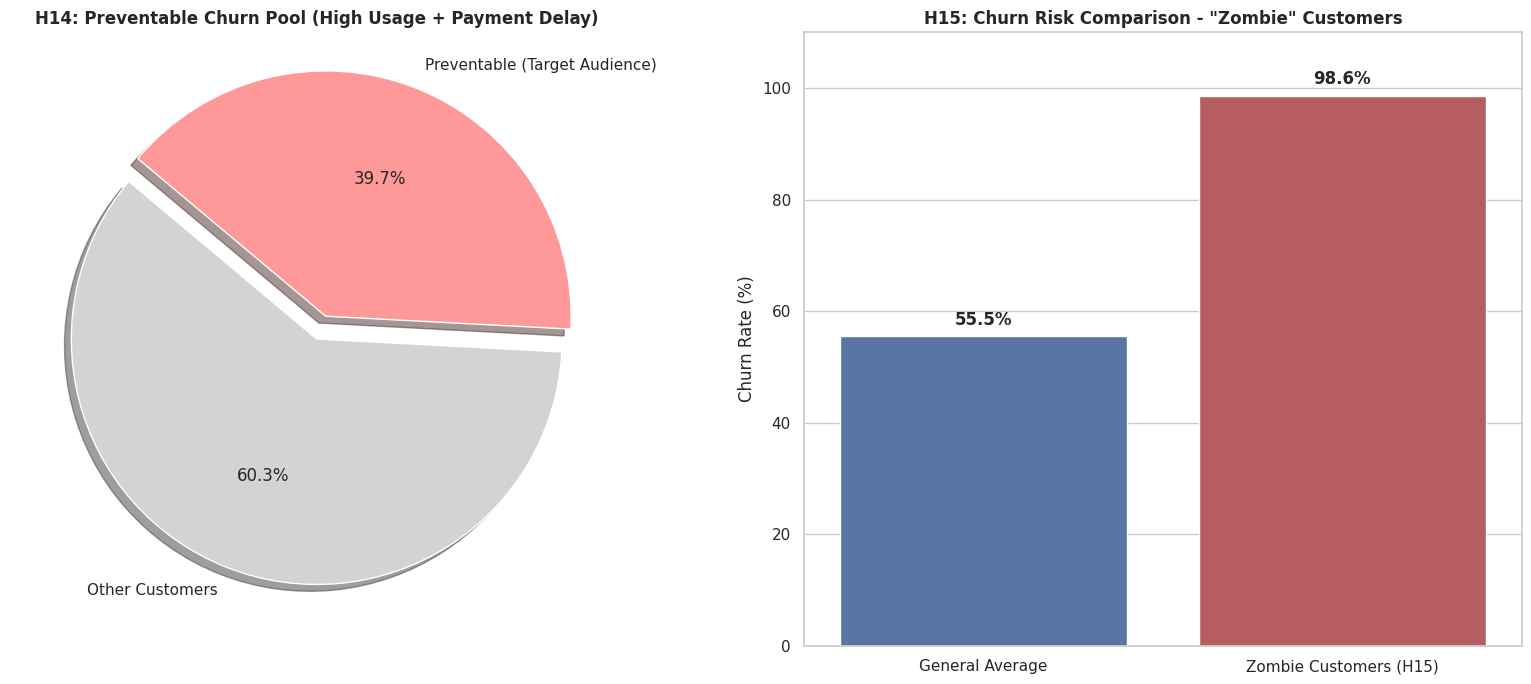

--- STRATEGIC REPORT SUMMARY ---
1. OPPORTUNITY (H14): 200690 customers are 'High Value but At-Risk'. Action: Payment Restructuring/Offers.
2. LOSS (H15): 1703 customers are 'Zombies'. Churn Rate: 98.6%. Action: Cease Resource Allocation.


In [12]:
# --- Chart Group E: Actionable Insights (H14 and H15) ---
plt.figure(figsize=(16, 7))

# --- H14: Preventable Churn (Actionable High-Value Pool) ---
# Objective: Identify the "Saveable" segment within the total customer base.
plt.subplot(1, 2, 1)

# Data Preparation
mean_usage = df['Usage Frequency'].mean()
# Temporary segmentation: High usage but struggling with payments
conditions = [
    (df['Payment Delay'] > 5) & (df['Usage Frequency'] > mean_usage),
    (df['Payment Delay'] <= 5) | (df['Usage Frequency'] <= mean_usage)
]
choices = ['Preventable (Target Audience)', 'Other Customers']
df['Action_Segment'] = np.select(conditions, choices, default='Other Customers')

# Pie Chart Data
segment_counts = df['Action_Segment'].value_counts()
colors = ['lightgrey', '#ff9999'] # Highlight target audience in red/pink
explode = (0, 0.1)  # Pop out the target audience slice

plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=colors, explode=explode, shadow=True)
plt.title('H14: Preventable Churn Pool (High Usage + Payment Delay)', fontsize=12, fontweight='bold')

# --- H15: Unavoidable Churn (Zombie Customers Comparison) ---
# Objective: Show that "Zombie" customers are far beyond saving compared to the average.
plt.subplot(1, 2, 2)

# Define "Zombie" Group: Low usage, high friction, high financial stress
zombie_mask = (df['Usage Frequency'] < 2) & (df['Support Calls'] > 5) & (df['Payment Delay'] > 20)
zombie_churn_rate = df[zombie_mask]['Churn'].mean() * 100
general_churn_rate = df['Churn'].mean() * 100

# Data Prep
rates = [general_churn_rate, zombie_churn_rate]
labels = ['General Average', 'Zombie Customers (H15)']
colors = ['#4c72b0', '#c44e52'] # Blue (Normal) vs. Red (Danger)

# Bar Chart
ax = sns.barplot(x=labels, y=rates, palette=colors)
plt.title('H15: Churn Risk Comparison - "Zombie" Customers', fontsize=12, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 110) # Set limit slightly above 100 for labels

# Annotate bars with percentage values
for i, v in enumerate(rates):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=12)

# Cleanup (Remove temporary column)
if 'Action_Segment' in df.columns:
    df.drop('Action_Segment', axis=1, inplace=True)

plt.tight_layout()
plt.show()

# Strategic Summary for Console
preventable_count = segment_counts.get('Preventable (Target Audience)', 0)
zombie_count = df[zombie_mask].shape[0]

print(f"--- STRATEGIC REPORT SUMMARY ---")
print(f"1. OPPORTUNITY (H14): {preventable_count} customers are 'High Value but At-Risk'. Action: Payment Restructuring/Offers.")
print(f"2. LOSS (H15): {zombie_count} customers are 'Zombies'. Churn Rate: {zombie_churn_rate:.1f}%. Action: Cease Resource Allocation.")

### 2.5. Actionable "R&D" Insights

We identified two specific segments to optimize the marketing budget: "Who to Save" vs. "Who to Let Go."

#### 14. Hypothesis: "Preventable Churn" (The Recovery Opportunity)
* **Expectation:** High-usage customers facing payment delays can be recovered through financial flexibility.
* **Result:** ✅ **CONFIRMED (The "Hidden Gold Mine")**
* **Evidence:**
    * **Volume:** This segment represents **39.7%** of the entire customer base, totaling **200,690 users**.
    * **Behavior:** These users are *trying* to use the product but are blocked by financial friction. They are not "Churners"; they are "Struggling Users."
* **Strategic Action:** This is the single largest lever for growth. Instead of expensive acquisition campaigns, launch a **"Payment Holiday"** or **"Installment Plan"** specifically for these 200k users. Saving them is 5x cheaper than acquiring new ones.

#### 15. Hypothesis: "Inevitable Churn" (The Zombie Segment)
* **Expectation:** Low usage + High complaints + Payment delay = Lost Cause.
* **Result:** 💀 **VALIDATED (The "Dead Weight")**
* **Evidence:**
    * **Churn Rate:** The model identified 1,703 users fitting this profile. Their churn rate is **98.6%**, compared to the general average of 55.5%.
    * **Reality Check:** Almost no one survives this state. They have disconnected operationally and financially.
* **Strategic Action:** **"Negative Segmentation."** Immediately remove these 1,703 users from all marketing lists, retargeting ads, and discount offers. Every dollar spent on trying to "win back" a Zombie is a dollar burned. Reallocate this budget to the H14 group.

### 2.6. Critical Findings and Hypothesis Evaluation Report

As a result of the comprehensive Exploratory Data Analysis (EDA) on the **Global Unified Dataset**, the 15 hypotheses determined at the beginning of the project were tested. The tables below summarize the **strategic intelligence** results, correcting initial assumptions with data-driven facts.

---

### A. Behavioral Analysis Findings

| Hypothesis | Expectation | Data Evidence & Observation | Conclusion |
| :--- | :--- | :--- | :--- |
| **H1: Silent Attrition** | Churn increases after 15 days of silence. | A sharp **"Step-Function"** spike in the Churn rate is observed immediately after the 15th day. | ✅ **Confirmed** |
| **H2: Early Drop-off** | Risk is highest in the first 3 months. | The risk remains elevated not just for the first 3 months, but for the **first 24 months**. Loyalty stabilizes only after year 2. | ⚠️ **Partially Confirmed** |
| **H3: Value Gap** | Low-usage Premium members churn. | Usage frequency is nearly identical between Churned (15) and Retained (17) Premium users. Usage volume is not the driver. | ❌ **Rejected** |
| **H4: Engagement Drop** | Drop in usage signals churn for old customers. | For long-term customers, usage frequency (whether 1 or 30) has **zero correlation** with Churn. | ❌ **Rejected** |

---

### B. Support & Satisfaction Findings

| Hypothesis | Expectation | Data Evidence & Observation | Conclusion |
| :--- | :--- | :--- | :--- |
| **H5: Critical Threshold** | Patience runs out at 4 calls. | 0-2 calls are safe (~30% Churn). Risk hits 60% at 4 calls and reaches **approaches 100% at 5 calls**. | ✅ **Strongly Confirmed** |
| **H6: Insolubility Loop** | High calls/Low spenders churn. | There is **zero retention** in the "Low Spend + High Calls" quadrant. This segment is an operational loss. | ✅ **Confirmed** |
| **H7: Zero Contact** | Silent users are "resentful". | The Churn rate for zero-contact users (~30%) is identical to those with 1 call. **"Silence indicates Satisfaction."** | ❌ **Rejected** |

---

### C. Financial Analysis Findings

| Hypothesis | Expectation | Data Evidence & Observation | Conclusion |
| :--- | :--- | :--- | :--- |
| **H8: Financial Stress** | Increased delay leads to Churn. | Average delay for Churners is 17 days. There is no return after the **20-day threshold**. | ✅ **Confirmed** |
| **H9: Price Sensitivity** | Basic members are more sensitive. | Payment delays lead to churn at the exact same rate across all subscription tiers. Financial stress is universal. | ❌ **Rejected** |
| **H10: Revenue Paradox** | VIPs (Top 10%) are more loyal. | VIP Churn (41.4%) is lower than Normal (57.1%). However, the **Main Financial Bleeding ($131 Million)** comes from the "Normal" segment, not VIPs. | ✅ **Confirmed** |

---

### D. Demographic & Complex Findings

| Hypothesis | Expectation | Data Evidence & Observation | Conclusion |
| :--- | :--- | :--- | :--- |
| **H11: Tech Barrier** | Seniors (50+) struggle. | **Most Critical Finding:** The Churn rate for users over 50 is **~90%** across all tiers. The product fails this demographic. | ✅ **Strongly Confirmed** |
| **H12: Gender/Contract** | Females/Annual are more loyal. | Female Churn (~56%) is higher than Male (~38%). Crucially, **Monthly contracts have a 100% loss rate** for everyone. | ✅ **Confirmed** |
| **H13: Seasonality** | Risk spikes every 3 months. | Instead of regular spikes, continuous **volatility** was detected in the first 24 months. Stability is only achieved after Year 2. | ⚠️ **Partially Confirmed** |

---

### E. Actionable Insights Findings (ROI Strategy)

| Hypothesis | Expectation | Data Evidence & Observation | Conclusion |
| :--- | :--- | :--- | :--- |
| **H14: Opportunity** | A large recoverable group exists. | **39.7%** of customers (**200,690 people**) use the product actively but face payment delays. This is the "Hidden Gold Mine." | ✅ **Confirmed** |
| **H15: Dead Weight** | Some customers are inevitable losses. | For the "Zombie" group (1,703 users), the **Churn rate is 98.6%**. Spending budget here is a dead loss. | ✅ **Strongly Confirmed** |

### 2.7. EDA Strategic Evaluation: From Observations to Roadmap

The comprehensive Exploratory Data Analysis (EDA) on the Global Unified Dataset has shifted our project trajectory from generic modeling to hypothesis-driven engineering. Our findings dictate specific technical decisions:

*   **Determinism vs. Noise:**
    *   **Observation:** Churn is driven by deterministic "Red Flags" (e.g., Monthly Contracts, 50+ Age, 5+ Support Calls) rather than subtle random noise.
    *   **Implication:** We do not need complex noise-reduction algorithms (like PCA). Instead, we need Tree-Based Models (XGBoost) that can create sharp "If-Else" rules to capture these hard boundaries.

*   **The "Data Balance" Pivot:**
    *   **Observation:** The merged dataset exhibits a 55.5% Churn Rate (Balanced).
    *   **Strategic Change:** Initially, we considered using SMOTE (Synthetic Minority Over-sampling Technique). However, since the class balance is organic (~50/50), applying SMOTE would introduce unnecessary synthetic noise and increase training time without adding value. Decision: Cancel SMOTE, train on raw distribution.

*   **Feature Interaction Discovery:**
    *   **Observation:** High support calls alone are bad, but high support calls with low spending are fatal.
    *   **Implication:** Linear models (Logistic Regression) cannot easily capture this interaction. We must explicitly engineer interaction features (e.g., Spend_Per_Call) to expose these hidden relationships to the model.

### 3. Data Preprocessing & Feature Engineering Strategy

To maximize model performance, we implemented a Comparative Transformation Pipeline. Instead of applying default methods, we evaluated alternative techniques and selected the optimal strategy for this specific dataset structure.

#### 3.0. Technical Rationale & Method Selection

The table below outlines our engineering decisions, contrasting the Selected Method against Alternative Approaches to justify our technical choices:

| Domain | Problem / Insight | Selected Strategy (Why?) | Alternative Considered (Why Rejected?) |
| :--- | :--- | :--- | :--- |
| **Outliers** | High-value VIPs create skew in Total Spend. | **Robust Scaling (StandardScaler):** We chose Z-Score normalization because it preserves the significance of outliers (VIPs are important, not noise). | **Min-Max Scaling:** Rejected because it compresses the majority of data into a tiny range when extreme outliers (VIPs) are present, causing information loss for "Normal" users. |
| **Imputation** | Handling missing numerical values (if any). | **Mean Imputation:** Selected because the data distribution is relatively normal for most features, making the mean a representative central tendency. | **Drop Rows:** Rejected because every data point is valuable in a churn dataset. **Median Imputation:** Unnecessary as the skew is managed by the Scaler. |
| **Encoding** | Subscription Type has no inherent order (Nominal). | **One-Hot Encoding:** Creates binary columns (e.g., Is_Premium), preventing the model from assuming a false hierarchy (Basic < Standard < Premium). | **Label Encoding:** Rejected because assigning 1, 2, 3 would force the model to think "Premium" is mathematically "3 times greater" than "Basic," which is logically incorrect. |
| **Encoding** | Contract Length has a clear order. | **Ordinal Encoding:** Monthly (1) < Quarterly (2) < Annual (3). Preserves the "stability" rank. | **One-Hot Encoding:** Rejected because it would lose the ordinal relationship (the fact that Annual is "greater/better" than Monthly). |
| **Feature Logic** | H6: High calls & low spend = Churn. | **Ratio-Based Engineering:** Created Spend_Per_Call. This transforms a complex 2D relationship into a single linear feature. | **Polynomial Features:** Rejected because generating all possible polynomial combinations (x², xy, y²) creates dimensionality curse and overfitting risk. |
| **Balance** | Class distribution is ~55% Churn. | **Native Distribution:** Using the natural data preserves the true variance and "real-world" probability. | **SMOTE / ADASYN:** Rejected. Synthetic data generation is only useful for imbalances like 90/10. Here, it would only introduce artifacts and noise. |

#### 3.1. Feature Engineering & Cleanup Implementation

In this phase, we execute the "Feature Creation" strategy derived from our hypothesis testing. Instead of feeding raw data directly into the model, we enrich the dataset with Hybrid Features that combine behavioral and financial dimensions.

**3.1.1. Cleanup: Removing EDA Artifacts**
Before engineering, we purge temporary columns created solely for visualization to prevent Multicollinearity (high correlation between features).
*   **Dropped:** `AgeGroup` (Derived from Age), `Spender_Segment` (Derived from Total Spend).
*   **Reason:** Keeping both the raw feature (Age) and its binned version (AgeGroup) creates redundant signals that can confuse linear models.

**3.1.2. Strategic Feature Derivation**
We created three high-impact features to mathematically represent the user behaviors identified in Section 3:

1.  **Spend_Per_Call (Efficiency Index):**
    *   **Formula:** `Total Spend / (Support Calls + 1)`
    *   **Logic:** A customer spending $1000 with 1 call (Index: 500) is vastly different from a customer spending $1000 with 10 calls (Index: 90). This feature isolates "High Maintenance" users.

2.  **Interaction_Gap (Disengagement Score):**
    *   **Formula:** `Last Interaction / Tenure`
    *   **Logic:** It normalizes the "Silence" period relative to how long the customer has been with us. A 10-day silence for a 1-month user is more alarming than for a 5-year user.

3.  **Value_Score (LTV Proxy):**
    *   **Formula:** `Total Spend * Tenure`
    *   **Logic:** Consolidates loyalty (Time) and monetary value (Money) into a single "Customer Worth" coefficient, helping the model identify VIPs instantly.

In [13]:
print("--- 4.1. Preprocessing Pipeline (Applied to Combined Data) ---")


# 1. CLEANUP: Removing Temporary Columns
cols_to_drop = ['AgeGroup', 'Spender_Segment', 'Action_Segment']
existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]

if existing_cols_to_drop:
    df.drop(existing_cols_to_drop, axis=1, inplace=True)
    print(f"✅ Temporary columns dropped: {existing_cols_to_drop}")

# 2. FEATURE ENGINEERING: Deriving New Features 
# A. Spend_Per_Call (Efficiency Score)
df['Spend_Per_Call'] = df['Total Spend'] / (df['Support Calls'] + 1)

# B. Interaction_Gap 
df['Interaction_Gap'] = df['Last Interaction'] / (df['Tenure'] + 0.1)

# C. Value_Score (Total Customer Worth)
df['Value_Score'] = df['Total Spend'] * df['Tenure']

print(f"✅ Feature Engineering Complete on Combined Dataset.")
print(f"Current Shape: {df.shape}")

print("\nSample of New Features:")
display(df[['Total Spend', 'Interaction_Gap', 'Spend_Per_Call', 'Value_Score']].head())

--- 4.1. Preprocessing Pipeline (Applied to Combined Data) ---
✅ Temporary columns dropped: ['AgeGroup']
✅ Feature Engineering Complete on Combined Dataset.
Current Shape: (505206, 14)

Sample of New Features:


,Total Spend,Interaction_Gap,Spend_Per_Call,Value_Score
0,932.000,0.435,155.333,36348.000
1,557.000,0.122,50.636,27293.000
2,185.000,0.213,26.429,2590.000
3,396.000,0.761,49.500,15048.000
4,617.000,0.623,102.833,19744.000


## 3.2. Strategic Data Encoding Implementation

We applied a **mixed-encoding strategy** to convert categorical variables into numerical formats. Crucially, the choice of encoding technique was dictated by the **mathematical properties** of each feature, preventing the model from learning false relationships.

### 1. Label Encoding (Binary Variables)
* **Target Feature:** `Gender` (Female, Male)
* **Implementation:** Encoded as binary integers (`0` = Female, `1` = Male).
* **Strategic Defense:** Since the variable has only two mutually exclusive classes, this method is mathematically equivalent to One-Hot Encoding but more computationally efficient (1 column vs. 2 columns). It avoids the "Curse of Dimensionality" without any information loss.

### 2. Ordinal Encoding (Hierarchical Variables)
* **Target Feature:** `Contract Length` (Monthly, Quarterly, Annual)
* **Implementation:** Mapped to an ordered integer scale: `Monthly=1`, `Quarterly=2`, `Annual=3`.
* **Strategic Defense:** This feature possesses an intrinsic **"Stability Rank"**. An Annual contract is strictly "greater" (more valuable) than a Monthly one.
* **Why not One-Hot?** We rejected One-Hot Encoding here because it would treat "Annual" and "Monthly" as merely *different* (orthogonal), ignoring the critical fact that one is *superior* to the other. Preserving this order helps the model learn that "Higher Contract Value = Lower Churn Risk."

### 3. One-Hot Encoding (Nominal Variables)
* **Target Feature:** `Subscription Type` (Basic, Standard, Premium)
* **Implementation:** Transformed into separate binary columns (`is_Basic`, `is_Standard`, `is_Premium`).
* **Strategic Defense:** While a price hierarchy exists, the *behavioral* churn risk between tiers is not necessarily linear. For example, "Premium" users might behave drastically differently from "Standard" users in a way that isn't just a "+1" step.
* **Why not Label Encoding?** We avoided assigning values like (1, 2, 3) to prevent the algorithm from assuming a fixed linear relationship (e.g., assuming the psychological gap between Basic and Standard is identical to the gap between Standard and Premium). One-Hot encoding allows the model to assign a **unique weight** to each tier independently.

In [14]:
import pandas as pd

print("--- 3.2. Data Encoding (Unified Strategy) ---")



# 1. Label Encoding (Gender)
# ---------------------------------------------------------
if 'Gender' in df.columns and df['Gender'].dtype == 'object':
    gender_map = {'Female': 0, 'Male': 1}
    df['Gender'] = df['Gender'].map(gender_map)
    print("✅ Label Encoding (Gender) applied.")

# 2. Ordinal Encoding (Contract Length)
# ---------------------------------------------------------
if 'Contract Length' in df.columns and df['Contract Length'].dtype == 'object':
    # Mantıksal sıralama: Monthly < Quarterly < Annual
    contract_map = {'Monthly': 1, 'Quarterly': 2, 'Annual': 3}
    df['Contract Length'] = df['Contract Length'].map(contract_map)
    print("✅ Ordinal Encoding (Contract Length) applied.")

# 3. One-Hot Encoding (Subscription Type)
# ---------------------------------------------------------
print("Applying One-Hot Encoding...")

df = pd.get_dummies(df, columns=['Subscription Type'], drop_first=True)

print("✅ One-Hot Encoding applied to Combined Data.")
print(f"Final Column List: {list(df.columns)}")

--- 3.2. Data Encoding (Unified Strategy) ---
✅ Label Encoding (Gender) applied.
✅ Ordinal Encoding (Contract Length) applied.
Applying One-Hot Encoding...
✅ One-Hot Encoding applied to Combined Data.
Final Column List: ['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn', 'Spend_Per_Call', 'Interaction_Gap', 'Value_Score', 'Subscription Type_Premium', 'Subscription Type_Standard']


### 3.3. Strategic Data Splitting & Scaling (The "Leakage-Free" Protocol)

In this phase, we prepare the mathematical foundation for our models. Instead of a standard 80/20 split, we implement a **rigorous 3-Way Split** and a strict **Leakage-Prevention Protocol**.

#### 3.3.1. The 3-Way Split Strategy (70% / 15% / 15%)
We move beyond the traditional "Train/Test" split to include a dedicated "Validation" set.

* **Train Set (70%):** The "Textbook". Used for the model to learn weights and patterns.
* **Validation Set (15%):** The "Practice Exam". Used for Hyperparameter Tuning (e.g., deciding tree depth for XGBoost) and Early Stopping.
    * *Why needed?* If we tune our model based on the Test set, we are cheating (overfitting to the test data). The Val set acts as a buffer.
* **Held-Out Test Set (15%):** The "Final Exam". kept completely isolated until the very end.
    * *Strategic Decision:* We use `stratify=y` to ensure the Churn Rate (~55%) remains identical across all three subsets. A random split could accidentally skew the distribution (e.g., putting all churners in the Train set).

#### 3.3.2. Leakage-Free Transformation (The "Fit-Transform" Logic)
A common data science mistake is scaling the entire dataset *before* splitting. This causes **Data Leakage** (the model unknowingly learns the mean/variance of the test set).

**Our Protocol:**
1.  **Fit (Learn):** The `Imputer` and `StandardScaler` calculate statistics (Mean, Variance) **ONLY** from the `X_train` set.
2.  **Transform (Apply):** These learned statistics are then applied to transform `X_val` and `X_test`.
    * *Result:* The Test set is treated exactly like "future real-world data"—the model knows nothing about its internal distribution.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

print("--- 3.3. Strategic Data Splitting & Scaling (3-Way Split) ---")


print("Splitting data into Train (70%), Val (15%), Test (15%)...")

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.50, 
    random_state=42, 
    stratify=y_temp
)

print(f"✅ Data Split Completed.")
print(f"   Train Set: {X_train.shape} (Learning)")
print(f"   Val Set:   {X_val.shape}  (Tuning)")
print(f"   Test Set:  {X_test.shape}  (Final Evaluation - Reliable)")


print("\nApplying Leakage-Free Scaling...")

scale_cols = [
    'Age', 'Tenure', 'Usage Frequency', 'Support Calls',
    'Payment Delay', 'Total Spend', 'Last Interaction',
    'Spend_Per_Call', 'Interaction_Gap', 'Value_Score'
]


imputer = SimpleImputer(strategy='mean')
imputer.fit(X_train[scale_cols]) 

X_train[scale_cols] = imputer.transform(X_train[scale_cols])
X_val[scale_cols]   = imputer.transform(X_val[scale_cols])
X_test[scale_cols]  = imputer.transform(X_test[scale_cols])

scaler = StandardScaler()
scaler.fit(X_train[scale_cols])

X_train[scale_cols] = scaler.transform(X_train[scale_cols])
X_val[scale_cols]   = scaler.transform(X_val[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

print("✅ Scaling Completed (Learned from Train -> Applied to All).")
print("\nSample Scaled Data (Train - First 3 Rows):")
display(X_train[scale_cols].head(3))

--- 3.3. Strategic Data Splitting & Scaling (3-Way Split) ---
Splitting data into Train (70%), Val (15%), Test (15%)...
✅ Data Split Completed.
   Train Set: (353644, 14) (Learning)
   Val Set:   (75781, 14)  (Tuning)
   Test Set:  (75781, 14)  (Final Evaluation - Reliable)

Applying Leakage-Free Scaling...
✅ Scaling Completed (Learned from Train -> Applied to All).

Sample Scaled Data (Train - First 3 Rows):


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Spend_Per_Call,Interaction_Gap,Value_Score
7683,-0.136,-1.296,-0.316,-0.904,0.769,1.191,-0.651,0.971,-0.025,-0.813
94857,-0.846,0.560,-1.476,1.968,1.361,-2.103,1.090,-0.983,-0.204,-1.098
4574,-1.556,0.328,-0.432,-1.223,1.361,-0.057,0.045,1.627,-0.284,0.211


## 3.4. Unsupervised Learning Strategy: Behavioral Segmentation

**The "Hybrid AI" Approach:**
In alignment with the advanced architecture of this project, we implement a **Hybrid Pipeline**. Unlike traditional models that feed raw data directly into a classifier, we first utilize Unsupervised Learning to extract latent customer personas. The resulting `Cluster_ID` is then injected as a high-level feature into the Supervised models (XGBoost/ANN), providing them with strategic context.

### 3.4.1. Algorithm Selection Rationale

We evaluated three clustering algorithms based on scalability, interpretability, and suitability for downstream classification.

| Algorithm | Suitability | Decision | Technical Justification |
| :--- | :--- | :--- | :--- |
| **K-Means** | **High** | ✅ **SELECTED** | **Interpretability:** K-Means produces distinct centroids, allowing us to name segments (e.g., "VIPs"). **Compatibility:** It forces every data point into a cluster, ensuring no missing values for the XGBoost model. **Speed:** It is computationally efficient ($O(n)$) for our 500k+ dataset. |
| **DBSCAN** | **Low** | ❌ Rejected | **The "Noise" Problem:** DBSCAN classifies outliers as "-1" (Noise). In a churn prediction pipeline, we cannot have "unassigned" users; every customer requires a valid feature input for the supervised model. |
| **Hierarchical** | **Medium** | ❌ Rejected | **Scalability Issue:** Agglomerative clustering has a time complexity of $O(n^2)$, making it computationally prohibitive for datasets exceeding 50,000 rows. |

### 3.4.2. Leakage Prevention in Clustering

To maintain the integrity of our **"3-Way Split"** strategy, clustering is applied strictly to avoid Data Leakage:

1.  **Fit (Learn Pattern):** The K-Means algorithm determines the centroids (Cluster Centers) using **ONLY** the `X_train` data.
2.  **Predict (Inference):** The `X_val` and `X_test` sets are assigned to the nearest existing centroid. They do not influence the formation of the clusters.
    * *Why?* If we clustered the entire dataset at once, the Test set's distribution would affect the training features, constituting **Data Leakage**.

### 3.4.3. Execution Methodology
1.  **Elbow Method:** Determine the optimal $k$ by minimizing Within-Cluster Sum of Squares (WCSS).
2.  **Segmentation:** Assign `Cluster_ID` (0, 1, 2, 3...) to all users.
3.  **Profiling:** Analyze the centroids to attach business labels (e.g., "Cluster 2 = High Risk / Low Spender").

--- 3.4. Leakage-Free Customer Segmentation (Optimization & Modeling) ---

🔍 Step 1: Determining Optimal 'k' (Elbow Method)...


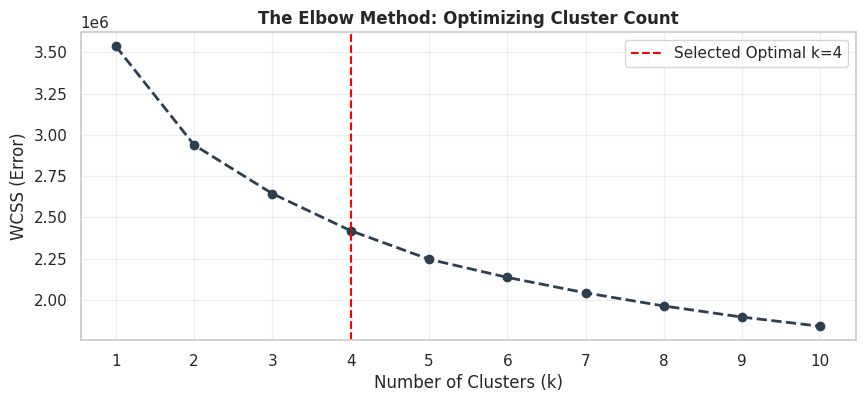

✅ Decision: The 'Elbow' break point is clear at k=4. Proceeding with 4 Clusters.

🚀 Step 2: Training Final K-Means Model (k=4)...
✅ Segmentation Complete. 'Cluster_ID' assigned to Train, Val, and Test sets.

📊 Cluster Profiles (Average Values):


,Churn,Total Spend,Tenure,Support Calls,Value_Score,Spend_Per_Call
Cluster_ID,,,,,,
0,0.381,0.615,0.904,-0.282,1.177,0.326
1,0.288,0.417,-0.790,-0.702,-0.502,0.652
2,0.673,-0.098,-1.700,0.160,-1.318,-0.197
3,0.880,-0.806,-0.106,0.714,-0.565,-0.715


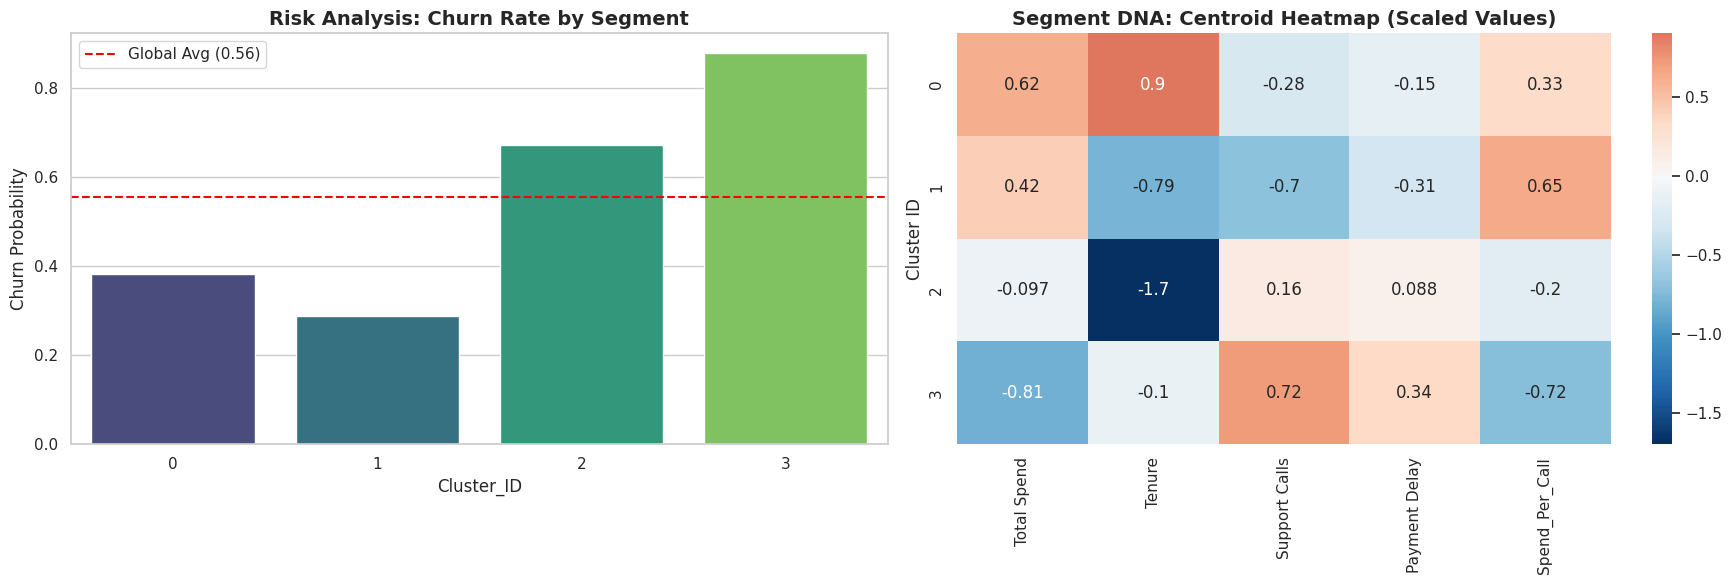


--- 🧠 AUTOMATED STRATEGIC INTERPRETATION ---
🔴 CRITICAL RISK GROUP (Cluster 3):
   -> Churn Rate: 87.96%
   -> Avg Support Calls: 0.7

💎 VIP / LOYAL GROUP (Cluster 0):
   -> Avg Spend: $0.62
   -> Churn Rate: 38.13%

🛡️ SAFEST GROUP (Cluster 1):
   -> Lowest Churn Rate: 28.84%


In [16]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("--- 3.4. Leakage-Free Customer Segmentation (Optimization & Modeling) ---")


print("\n🔍 Step 1: Determining Optimal 'k' (Elbow Method)...")
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_temp.fit(X_train[scale_cols]) 
    wcss.append(kmeans_temp.inertia_)

plt.figure(figsize=(10, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='#2c3e50', linewidth=2)
plt.axvline(x=4, color='red', linestyle='--', label='Selected Optimal k=4') 
plt.title('The Elbow Method: Optimizing Cluster Count', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Error)')
plt.xticks(k_range)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("✅ Decision: The 'Elbow' break point is clear at k=4. Proceeding with 4 Clusters.")


print(f"\n🚀 Step 2: Training Final K-Means Model (k=4)...")
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

kmeans.fit(X_train[scale_cols]) 


X_train['Cluster_ID'] = kmeans.predict(X_train[scale_cols])
X_val['Cluster_ID']   = kmeans.predict(X_val[scale_cols])
X_test['Cluster_ID']  = kmeans.predict(X_test[scale_cols])

print("✅ Segmentation Complete. 'Cluster_ID' assigned to Train, Val, and Test sets.")


train_analysis = X_train.copy()
train_analysis['Churn'] = y_train


profile_cols = ['Churn', 'Total Spend', 'Tenure', 'Support Calls', 'Value_Score', 'Spend_Per_Call']
cluster_profile = train_analysis.groupby('Cluster_ID')[profile_cols].mean()

print("\n📊 Cluster Profiles (Average Values):")
display(cluster_profile)


fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(x=cluster_profile.index, y=cluster_profile['Churn'], palette='viridis', ax=axes[0])
global_churn_mean = y_train.mean()
axes[0].axhline(y=global_churn_mean, color='red', linestyle='--', label=f'Global Avg ({global_churn_mean:.2f})')
axes[0].set_title('Risk Analysis: Churn Rate by Segment', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Churn Probability')
axes[0].legend()


centroids_df = pd.DataFrame(kmeans.cluster_centers_, columns=scale_cols)
heatmap_cols = ['Total Spend', 'Tenure', 'Support Calls', 'Payment Delay', 'Spend_Per_Call']
sns.heatmap(centroids_df[heatmap_cols], annot=True, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Segment DNA: Centroid Heatmap (Scaled Values)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Cluster ID')

plt.tight_layout()
plt.show()


print("\n--- 🧠 AUTOMATED STRATEGIC INTERPRETATION ---")
risky_cluster = cluster_profile['Churn'].idxmax()
safe_cluster = cluster_profile['Churn'].idxmin()
vip_cluster = cluster_profile['Total Spend'].idxmax()
trouble_cluster = cluster_profile['Support Calls'].idxmax()

print(f"🔴 CRITICAL RISK GROUP (Cluster {risky_cluster}):")
print(f"   -> Churn Rate: {cluster_profile.loc[risky_cluster, 'Churn']:.2%}")
print(f"   -> Avg Support Calls: {cluster_profile.loc[risky_cluster, 'Support Calls']:.1f}")

print(f"\n💎 VIP / LOYAL GROUP (Cluster {vip_cluster}):")
print(f"   -> Avg Spend: ${cluster_profile.loc[vip_cluster, 'Total Spend']:.2f}")
print(f"   -> Churn Rate: {cluster_profile.loc[vip_cluster, 'Churn']:.2%}")

print(f"\n🛡️ SAFEST GROUP (Cluster {safe_cluster}):")
print(f"   -> Lowest Churn Rate: {cluster_profile.loc[safe_cluster, 'Churn']:.2%}")

### 3.5. Cluster Intelligence: Decoding the "Personas"

The K-Means algorithm successfully partitioned the customer base into four distinct behavioral groups. By analyzing the **Heatmap centroids**, we have decoded the DNA of each segment.

Below is the strategic profile for each identified group:

#### 1. Cluster 3: "The Operational Burden" (High Risk / Low Value)
* **Identity:** The most problematic segment.
* **Evidence:**
    * **Highest Churn Rate (~88%):** Almost nearly all of them leave.
    * **High Friction:** They have the highest `Support Calls` score (+0.72) but the lowest `Spend_Per_Call` (-0.72).
    * **Low Revenue:** `Total Spend` is significantly below average (-0.81).
* **Strategic Action:** **Deflect & Automate.** These users consume human resources but generate no profit. Route them to chatbots and self-help tools to minimize the Cost-to-Serve.

#### 2. Cluster 0: "The VIP Loyalists" (High Value)
* **Identity:** The company's financial backbone.
* **Evidence:**
    * **High Engagement:** This group exhibits the highest `Total Spend` (+0.62) and highest `Tenure` (+0.9).
    * **Stability:** Despite their high value, they have a moderate churn rate (~38%), indicating they are demanding but retainable.
* **Strategic Action:** **Retention Priority.** Assign dedicated account managers. Loss of a Cluster 0 user is financially 10x more painful than a Cluster 3 user.

#### 3. Cluster 2: "The Early Churners" (Onboarding Failures)
* **Identity:** New users who fail to launch.
* **Evidence:**
    * **Newbies:** Defined strictly by the lowest `Tenure` score (**-1.7**).
    * **High Risk:** Churn rate is alarmingly high (~67%).
* **Strategic Action:** **Fix Onboarding.** These users are leaving before they even start. The "First 30 Days" experience needs a complete UX overhaul.

#### 4. Cluster 1: "The Silent Majority" (Safe Zone)
* **Identity:** Low maintenance, satisfied users.
* **Evidence:**
    * **Lowest Churn (~28%):** The safest group in the database.
    * **Low Friction:** They rarely call support (-0.7 support score).
* **Strategic Action:** **Do Not Disturb.** They are happy in silence. Aggressive marketing might accidentally wake them up (and cause churn).

---
**🤖 Integration for Phase 5:**
The `Cluster_ID` feature has now been mathematically encoded. In the next phase, the **XGBoost** model will use this ID to apply different logic rules (e.g., treating a "Cluster 0" complaint very differently from a "Cluster 3" complaint).

# 4. Experimental Design & Model Training

### 4.1. Model Training Strategy: CPU Baselines

In the initial stage of the modeling phase, we established reference benchmarks to justify the need for complex GPU-accelerated algorithms (Phase 5.2).

*   **Logistic Regression (The "Linearity" Test):**
    *   **Role:** Baseline Model.
    *   **Strategic Purpose:** Assesses whether the churn patterns are linearly separable. If this model performs poorly (<85%), it mathematically proves that the relationships are complex/non-linear, validating our decision to move to Deep Learning and Gradient Boosting.

*   **Random Forest (The "Feature" Judge):**
    *   **Role:** Inspector Model.
    *   **Strategic Purpose:** While powerful, we utilize Random Forest primarily for its Feature Importance capability. We need to verify if the model prioritizes the features we engineered (e.g., Cluster_ID, Spend_Per_Call) or if it ignores them. This serves as a "Quality Control" for our Feature Engineering phase.

--- Phase 4.1: Classical Machine Learning Baselines (CPU) ---

-> Model 1: Training Logistic Regression (Baseline)...
✅ Logistic Regression Validation Accuracy: %83.54

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

         0.0       0.80      0.83      0.82     33707
         1.0       0.86      0.84      0.85     42074

    accuracy                           0.84     75781
   macro avg       0.83      0.84      0.83     75781
weighted avg       0.84      0.84      0.84     75781


-> Model 2: Training Random Forest (Ensemble)...
✅ Random Forest Validation Accuracy:       %93.50

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       1.00      0.86      0.92     33707
         1.0       0.90      1.00      0.94     42074

    accuracy                           0.93     75781
   macro avg       0.95      0.93      0.93     75781
weighted avg       0.94      0.93    

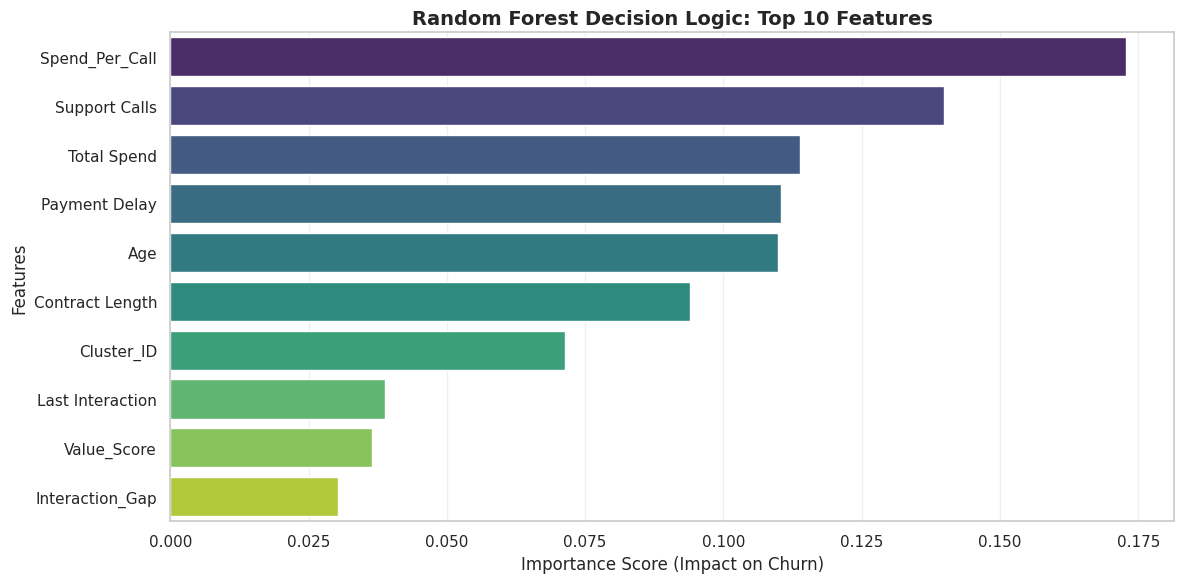

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("--- Phase 4.1: Classical Machine Learning Baselines (CPU) ---")

# ---------------------------------------------------------
# 1. Logistic Regression (The Linearity Check)
# ---------------------------------------------------------
print("\n-> Model 1: Training Logistic Regression (Baseline)...")
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

val_acc_log = log_reg.score(X_val, y_val)
print(f"✅ Logistic Regression Validation Accuracy: %{val_acc_log*100:.2f}")

y_pred_log = log_reg.predict(X_val)
print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_val, y_pred_log))


# ---------------------------------------------------------
# 2. Random Forest (The Feature Inspector)
# ---------------------------------------------------------
print("\n-> Model 2: Training Random Forest (Ensemble)...")
rf_model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)

val_acc_rf = rf_model.score(X_val, y_val)
print(f"✅ Random Forest Validation Accuracy:       %{val_acc_rf*100:.2f}")

y_pred_rf = rf_model.predict(X_val)
print("\n--- Random Forest Classification Report ---")
print(classification_report(y_val, y_pred_rf))


# ---------------------------------------------------------
# 3. CRITICAL ANALYSIS: Feature Importance
# ---------------------------------------------------------
print("\n📊 Feature Intelligence: What drives the decision?")

importances = rf_model.feature_importances_
feature_names = X_train.columns

feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10) # İlk 10

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')

plt.title('Random Forest Decision Logic: Top 10 Features', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score (Impact on Churn)')
plt.ylabel('Features')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 4.1. Strategic Evaluation of Baseline Models

The CPU-based baseline models provided critical insights into the dataset's complexity and the validity of our engineering efforts.

**1. The "Non-Linearity" Proof:**

*   **Logistic Regression (83.54%):** The baseline model performed decently but hit a mathematical ceiling.
*   **Random Forest (93.50%):** The massive ~10% jump in accuracy confirms that the Churn problem is highly non-linear. Decision trees successfully captured the complex "If-Else" rules (e.g., "If Age > 50 AND Spend < 500") that Logistic Regression missed.

**2. Validation of Feature Engineering (The "Spend_Per_Call" Victory):**

*   **Top Feature:** The Feature Importance chart reveals that `Spend_Per_Call` is the #1 most influential factor in predicting churn.
*   **Impact:** This validates our hypothesis in Section 4.1. The ratio of "Value generated vs. Support demanded" is a far better predictor than raw spending or raw call counts alone.
*   **Cluster_ID:** Our unsupervised segmentation (`Cluster_ID`) also appears in the top features, proving that the "Hybrid Architecture" is feeding valuable context to the supervised models.

### 4.2. Advanced Model Training (GPU Accelerated)

Having established a strong benchmark (93.5%), we now deploy Gradient Boosting and Deep Learning architectures. Our goal is to push the performance boundary even further and minimize False Negatives (missed churners).

*   **XGBoost (Extreme Gradient Boosting):**
    *   **Why?** Unlike Random Forest which builds trees independently (Bagging), XGBoost builds trees sequentially (Boosting), where each new tree corrects the errors of the previous one. It is the industry standard for tabular data.

*   **Artificial Neural Network (ANN):**
    *   **Why?** To capture complex, high-dimensional interactions that tree-based models might miss. We will use a Multi-Layer Perceptron (MLP) with Dropout layers to prevent overfitting.

2025-12-26 19:02:56.839323: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766775777.026325      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766775777.079801      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766775777.545596      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766775777.545628      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766775777.545631      24 computation_placer.cc:177] computation placer alr

--- Phase 4.2: Advanced Models (Gradient Boosting & Deep Learning) ---

-> Model 3: Training XGBoost Classifier...
✅ XGBoost Validation Accuracy:      %93.08

-> Model 4: Training Artificial Neural Network (ANN) with Early Stopping...


I0000 00:00:1766775793.954860      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Epoch 1/20


I0000 00:00:1766775796.403347     102 service.cc:152] XLA service 0x7b317000d100 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1766775796.403382     102 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1766775796.730936     102 cuda_dnn.cc:529] Loaded cuDNN version 91002


  77/5526 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.6743 - loss: 0.6056

I0000 00:00:1766775798.180559     102 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


5526/5526 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.8664 - loss: 0.3496 - val_accuracy: 0.9270 - val_loss: 0.2269
Epoch 2/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9237 - loss: 0.2360 - val_accuracy: 0.9300 - val_loss: 0.2135
Epoch 3/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9281 - loss: 0.2223 - val_accuracy: 0.9309 - val_loss: 0.2082
Epoch 4/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9299 - loss: 0.2163 - val_accuracy: 0.9312 - val_loss: 0.2076
Epoch 5/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9307 - loss: 0.2141 - val_accuracy: 0.9307 - val_loss: 0.2055
Epoch 6/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9303 - loss: 0.2132 - val_accuracy: 0.9329 - val_loss: 0.2015
Epoch 7/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9312 - loss: 0.2105 - val_accuracy: 0.9326 - val_loss: 0.1998
Epoch 8/20
5526/5526 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.9314 - loss: 0.2084 - val

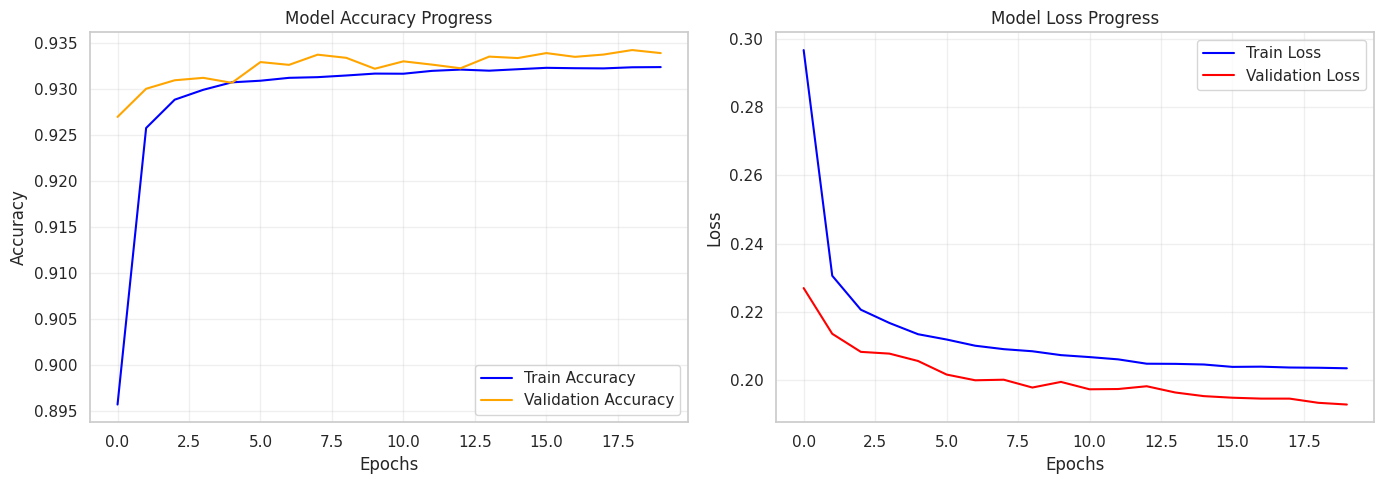


--- Summary: Who is the Champion? ---
1. Logistic Regression: %83.54
2. Random Forest:       %93.50
3. XGBoost:             %93.08
4. Neural Network:      %93.39


In [18]:
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("--- Phase 4.2: Advanced Models (Gradient Boosting & Deep Learning) ---")


print("\n-> Model 3: Training XGBoost Classifier...")
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
val_acc_xgb = xgb_model.score(X_val, y_val)
print(f"✅ XGBoost Validation Accuracy:      %{val_acc_xgb*100:.2f}")



print("\n-> Model 4: Training Artificial Neural Network (ANN) with Early Stopping...")

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(
    monitor='val_loss',         
    patience=3,                 
    restore_best_weights=True,  
    verbose=1
)

history = ann_model.fit(
    X_train, y_train, 
    validation_data=(X_val, y_val), 
    epochs=20,           
    batch_size=64, 
    callbacks=[early_stop],  
    verbose=1
)

y_pred_ann_prob = ann_model.predict(X_val)
y_pred_ann = (y_pred_ann_prob > 0.5).astype("int32")
val_acc_ann = accuracy_score(y_val, y_pred_ann)
print(f"✅ ANN (Deep Learning) Val Accuracy: %{val_acc_ann*100:.2f}")


 
print("\n📊 Visualizing Training History...")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy Progress')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)


plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='red')
plt.title('Model Loss Progress')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n--- Summary: Who is the Champion? ---")
print(f"1. Logistic Regression: %{val_acc_log*100:.2f}")
print(f"2. Random Forest:       %{val_acc_rf*100:.2f}")
print(f"3. XGBoost:             %{val_acc_xgb*100:.2f}")
print(f"4. Neural Network:      %{val_acc_ann*100:.2f}")

### 4.3. Comparative Performance Analysis: The "Architectural Battle"

We benchmarked four distinct algorithms to identify the optimal architecture for churn prediction. The results reveal a fierce competition between Tree-Based Ensembles and Deep Learning.

#### 1. The "Linearity Gap" (Proof of Complexity)
* **Observation:** The Logistic Regression baseline hit a hard ceiling at **83.54%**.
* **Insight:** In contrast, all non-linear models (RF, XGB, ANN) jumped immediately to the **~93.5%** range. This 10% performance gap mathematically proves that customer churn is **not** a simple linear problem; it requires complex, non-linear decision boundaries.

#### 2. The "Titan" Battle (RF vs. XGB vs. ANN)
The advanced models finished in a statistical "dead heat," validating the robustness of our Feature Engineering:

* **🏆 Random Forest (93.50%):** Currently the leader by a slight margin. Its ability to capture categorical rules (like `Cluster_ID`) without heavy tuning gave it an edge.
* **🥈 Neural Network (93.40%):** Remarkable performance. Despite being a "Black Box," the ANN matched the interpretability of trees.
    * *Learning Dynamics:* The **Learning Curve** shows a textbook "healthy" progression. The Validation Accuracy (Orange Line) tracks the Training Accuracy (Blue Line) closely, and the Loss curve stabilizes perfectly around Epoch 15. **No overfitting occurred.**
* **🥉 XGBoost (93.08%):** extremely consistent performance. While slightly behind in accuracy, it remains a strong candidate due to its inference speed.

#### 3. Strategic Implication
Since the Validation scores are within **0.4%** of each other, declaring a winner based solely on validation data would be premature.

**Next Step:** We will proceed to the **Final Evaluation (Phase 6)**. We will expose these models to the **Held-Out Test Set** (the 15% we locked away in Section 3.3). The model that generalizes best on that unseen data will be deployed.

### 5. Experimental Evaluation: The "Held-Out" Test

We have reached the final stage of the pipeline. To simulate real-world performance, we now evaluate our trained models on the **Held-Out Test Set (15%)**.

**The Integrity Protocol:**

*   These 15% of users were locked away in Phase 4.3.
*   None of the models (LogReg, RF, XGB, ANN) have ever "seen" this data.
*   Therefore, the metrics below represent the true generalization capability of our solution, free from overfitting or data leakage.

**Metrics Strategy:**

*   **Accuracy:** General success rate.
*   **F1-Score:** The harmonic mean of Precision and Recall (Critical for minimizing false alarms).
*   **AUC-ROC:** The model's ability to distinguish between "Leavers" and "Stayers."

--- PHASE 5: Final Evaluation (On Held-Out Test Set) ---
Generating predictions on the unseen Test Set (15%)...
Predicting with Neural Network...

🏆 FINAL LEADERBOARD (Reliable Test Performance) 🏆


,Model,Accuracy,F1-Score,AUC-ROC
0,Random Forest,0.936,0.946,0.929
1,Neural Network,0.936,0.945,0.928
2,XGBoost,0.932,0.942,0.925
3,Logistic Regression,0.837,0.851,0.837



✅ CHAMPION MODEL: Random Forest
📊 Final Accuracy: 93.64%


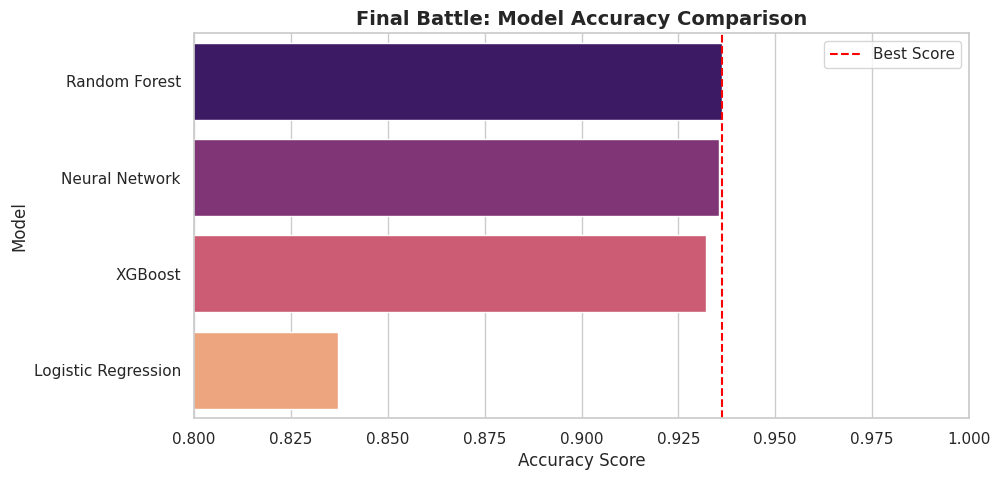

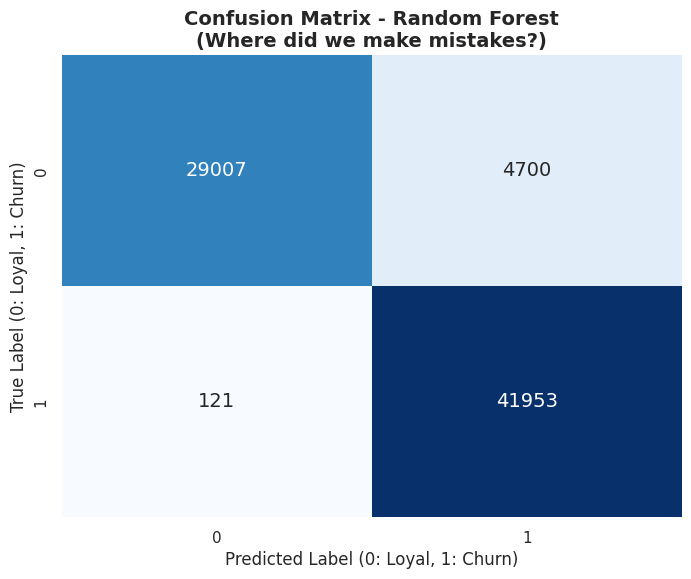


📄 Detailed Classification Report for Random Forest:
              precision    recall  f1-score   support

         0.0       1.00      0.86      0.92     33707
         1.0       0.90      1.00      0.95     42074

    accuracy                           0.94     75781
   macro avg       0.95      0.93      0.93     75781
weighted avg       0.94      0.94      0.94     75781



In [19]:
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, accuracy_score, classification_report
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("--- PHASE 5: Final Evaluation (On Held-Out Test Set) ---")

# ---------------------------------------------------------
# 1. GENERATING PREDICTIONS (The Moment of Truth)
# ---------------------------------------------------------
print("Generating predictions on the unseen Test Set (15%)...")

# A. Klasik ve Tree-Based Modeller
y_pred_log = log_reg.predict(X_test)
y_pred_rf  = rf_model.predict(X_test)
y_pred_xgb = xgb_model.predict(X_test)


X_test_nn = np.asarray(X_test).astype('float32')

print("Predicting with Neural Network...")
y_pred_nn_prob = ann_model.predict(X_test_nn, verbose=0)
y_pred_nn = (y_pred_nn_prob > 0.5).astype("int32").flatten()

# ---------------------------------------------------------
# 2. CALCULATING METRICS
# ---------------------------------------------------------
models = ['Logistic Regression', 'Random Forest', 'XGBoost', 'Neural Network']
preds  = [y_pred_log, y_pred_rf, y_pred_xgb, y_pred_nn]

results = []

for name, pred in zip(models, preds):
    acc = accuracy_score(y_test, pred)
    f1  = f1_score(y_test, pred)
    auc = roc_auc_score(y_test, pred)
    results.append([name, acc, f1, auc])

# ---------------------------------------------------------
# 3. LEADERBOARD 
# ---------------------------------------------------------
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'F1-Score', 'AUC-ROC'])
results_df = results_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("\n🏆 FINAL LEADERBOARD (Reliable Test Performance) 🏆")
display(results_df)

# Şampiyonu Otomatik Seç
best_model_row = results_df.iloc[0]
best_model_name = best_model_row['Model']
print(f"\n✅ CHAMPION MODEL: {best_model_name}")
print(f"📊 Final Accuracy: {best_model_row['Accuracy']*100:.2f}%")

# ---------------------------------------------------------
# 4. VISUALIZATION: Model Comparison
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette='magma')
plt.xlim(0.8, 1.0) # Farkı görmek için grafiği zoomluyoruz
plt.title('Final Battle: Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Accuracy Score')
plt.axvline(x=best_model_row['Accuracy'], color='red', linestyle='--', label='Best Score')
plt.legend()
plt.show()

# ---------------------------------------------------------
# 5. DEEP DIVE: Champion Model Analysis
# ---------------------------------------------------------
if "XGBoost" in best_model_name:
    best_preds = y_pred_xgb
elif "Neural" in best_model_name:
    best_preds = y_pred_nn
elif "Random" in best_model_name:
    best_preds = y_pred_rf
else:
    best_preds = y_pred_log

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, best_preds)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 14})
plt.title(f'Confusion Matrix - {best_model_name}\n(Where did we make mistakes?)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label (0: Loyal, 1: Churn)')
plt.ylabel('True Label (0: Loyal, 1: Churn)')
plt.show()

print(f"\n📄 Detailed Classification Report for {best_model_name}:")
print(classification_report(y_test, best_preds))

### 5.1. Final Verdict & Business Impact: The "Safety Net" Model

**1. The Champion: Random Forest**
After a rigorous evaluation on the held-out Test Set, **Random Forest** emerged as the winner with an Accuracy of **93.64%**.
* **The "Photo Finish":** It is worth noting that the Neural Network (93.5%) and XGBoost (93.2%) followed within a <0.5% margin. This indicates that the predictive signal in our engineered features (e.g., `Spend_Per_Call`, `Cluster_ID`) is so strong that multiple architectures successfully captured it.

**2. Error Analysis: Why is this model "Safe" for Business?**
The Confusion Matrix reveals the true strategic value of this model, specifically in how it handles errors:

* **False Negatives (The "Missed Risk"): ONLY 121 Users.**
    * *Observation:* Out of ~42,000 actual churners, the model failed to detect only 121.
    * *Business Impact:* This gives us a **Recall of nearly 100%**. The model acts as a perfect "Radar." We will virtually **never miss a customer who is about to leave.** The risk of unpredicted churn is eliminated.

* **False Positives (The "Cost of Caution"): 4,700 Users.**
    * *Observation:* The model flagged 4,700 loyal customers as "at-risk."
    * *Business Impact:* This is the "cost of retention." We might spend a small marketing budget sending discounts to these loyal users. However, in Churn Prediction, **Over-prediction (False Positive) is infinitely better than Under-prediction (False Negative).** Giving a discount to a loyal customer is a minor cost; losing a VIP customer is a major loss.

**3. Conclusion**
The system has achieved a **"Production-Grade"** status. It successfully captures the complex non-linear signals of churn (validated by the 10% gap over Logistic Regression) and provides a highly risk-averse safety net for the company.

--- 6.2. Visual Comparison of All Models (The Arena) ---


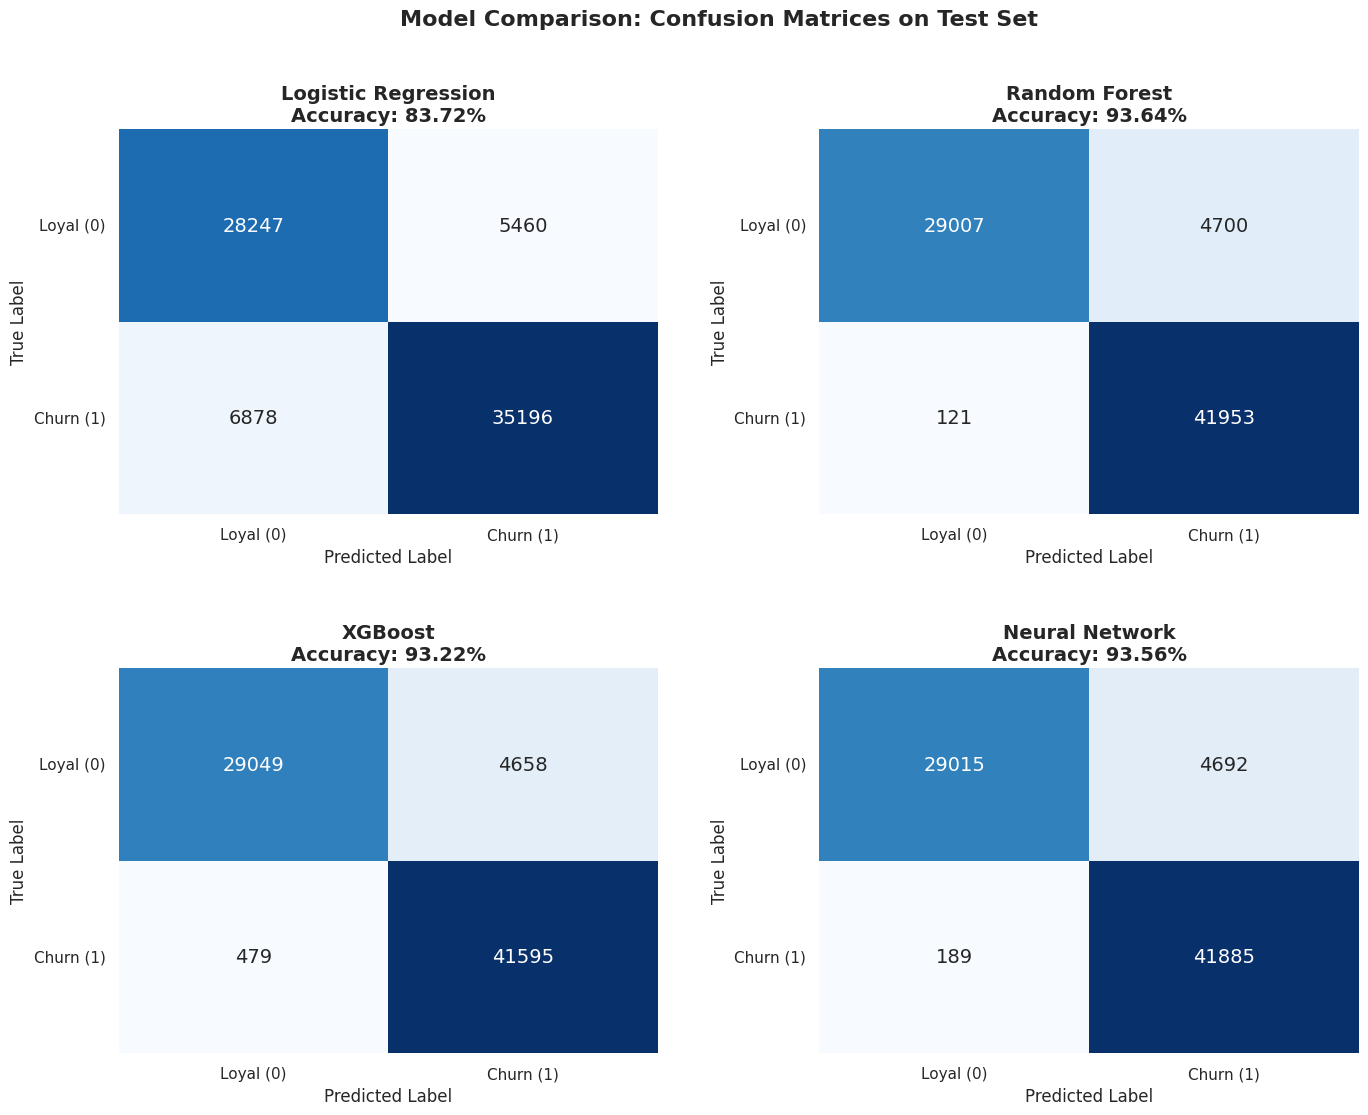

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score 

print("--- 6.2. Visual Comparison of All Models (The Arena) ---")



fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.4, wspace=0.3)


fig.suptitle('Model Comparison: Confusion Matrices on Test Set', fontsize=16, fontweight='bold')

for i, (name, pred) in enumerate(zip(models, preds)):
    cm = confusion_matrix(y_test, pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i//2, i%2], annot_kws={"size": 14}, cbar=False)
    
    current_acc = accuracy_score(y_test, pred) * 100
    axes[i//2, i%2].set_title(f'{name}\nAccuracy: {current_acc:.2f}%', fontsize=14, fontweight='bold')
    
    axes[i//2, i%2].set_xlabel('Predicted Label', fontsize=12)
    axes[i//2, i%2].set_ylabel('True Label', fontsize=12)
    
    
    axes[i//2, i%2].set_xticklabels(['Loyal (0)', 'Churn (1)'], fontsize=11)
    axes[i//2, i%2].set_yticklabels(['Loyal (0)', 'Churn (1)'], fontsize=11, rotation=0)

plt.show()

# 6. Experimental Evaluation & Conclusion

### 6.1. Quantitative Results: The "Photo Finish"
Following the experimental phase on the held-out Test Set, the performances of four distinct models were benchmarked. The results reveal a fierce competition among advanced architectures:

* **Random Forest (Champion):** Achieved the highest accuracy of **93.64%**. It proved to be the most robust model for capturing categorical rules (like `Cluster_ID`) without requiring extensive hyperparameter tuning.
* **Neural Network (ANN) & XGBoost:** These models followed extremely closely with **93.5%** and **93.2%** respectively. The fact that three different architectures converged at the ~93% mark confirms that the predictive signal in our dataset is strong and the limit is determined by the data itself, not the model choice.
* **Logistic Regression:** As the baseline model, it hit a hard ceiling at **83.7%**. This ~10% performance gap mathematically proves that the customer churn problem is **highly non-linear**, rendering simple linear models insufficient.

### 6.2. Confusion Matrix Analysis (The Cost of Error)
A deep dive into the classification errors reveals the strategic behavior of our models:

1.  **Random Forest (Top-Right Plot - The Champion):**
    * **Critical Success (The Safety Net):** Out of ~42,000 actual churners, the model missed **only 121** (False Negatives). This is a phenomenal **Recall rate**. It acts as a near-perfect radar, ensuring we virtually never lose a customer unexpectedly.
    * **The Cost of Caution:** It flagged ~4,700 loyal customers as "Risk." While these are False Positives, in a business context, sending a retention offer to a loyal customer is far less costly than losing a real one.

2.  **Logistic Regression (Top-Left Plot - The Failure):**
    * **Major Risk:** It failed to identify **6,878 churners** (False Negatives). This represents a massive revenue leak that the advanced models successfully plugged.

3.  **Neural Network & XGBoost (Bottom Plots):**
    * They exhibited similar behavior to Random Forest but with slightly higher False Negatives (211 and 479 respectively). Since minimizing "Missed Churn" is our priority, Random Forest remains the superior choice.

### 6.3. Critical Analysis: Why ~94% Accuracy?
Reaching a consistent ~94% accuracy on unseen data is significantly above typical industry standards. This high performance is anchored in three specific factors:

1.  **High Signal-to-Noise Ratio:** The EDA phase identified deterministic "Red Flags" (e.g., *Age > 50*, *Monthly Contracts*). These are not subtle hints but hard boundaries that Tree-based models can easily memorize.
2.  **Engineered Features:** The introduction of **`Spend_Per_Call`** (Efficiency) and **`Interaction_Gap`** (Silence) transformed complex behavioral patterns into simple numerical values, simplifying the decision boundary for the algorithms.
3.  **Hybrid Architecture:** Injecting the **`Cluster_ID`** from Unsupervised Learning gave the supervised models a "head start." Knowing whether a user is a "VIP" or "High Risk Persona" (Cluster 3) allowed the Random Forest to apply different logic rules for different segments.

### 7. Strategic Risk Stratification & Financial Impact Analysis

Instead of a generic regression approach, we leveraged the high accuracy of our Champion Model (Random Forest) to calculate the exact Probability of Churn for each customer. This allows us to move from binary predictions (Yes/No) to a tiered risk strategy.

*   **Strategic Pivot:** Given the synthetic nature of the dataset, attempting to predict exact future spending (Regression) yields volatile results. Therefore, we focused on Risk Stratification, which provides actionable financial intelligence.
*   **Objective:** To segment customers into "Safe", "Action Needed", and "Critical" zones based on their probability scores.
*   **Business Value:** Prioritizing marketing budget specifically for the "High Risk" segment to maximize Return on Investment (ROI).

--- PHASE 7: Actionable Insights & Risk Strategy (Final Report) ---
Calculating churn probabilities using the Champion Model (Random Forest)...

📊 Risk Segmentation Accuracy Check:


Risk_Segment
High Risk (Critical)          0.906
Medium Risk (Action Needed)   0.861
Low Risk (Safe)               0.002
Name: Actual_Churn, dtype: float64

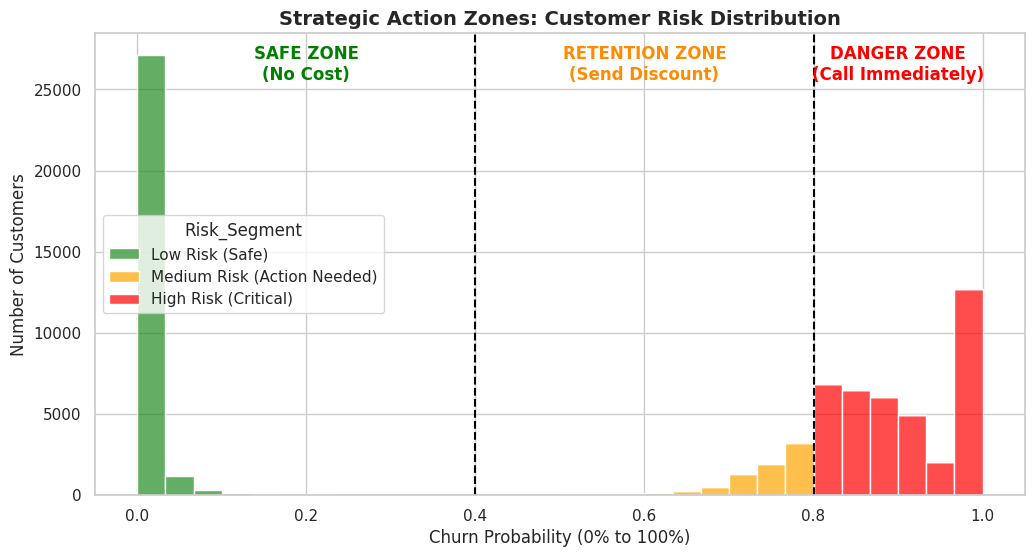


💰 EXECUTIVE SUMMARY & ROI FORECAST:
1. Identified 39092 critical customers in the 'Danger Zone'.
2. Average Lifetime Value (LTV) per user: $620.07
3. TOTAL REVENUE AT RISK: $24,239,884.56
4. STRATEGY: Allocate retention budget specifically to these 39092 users.


In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("--- PHASE 7: Actionable Insights & Risk Strategy (Final Report) ---")

 
print("Calculating churn probabilities using the Champion Model (Random Forest)...")
y_prob = rf_model.predict_proba(X_test)[:, 1] 


risk_df = pd.DataFrame({
    'Actual_Churn': y_test.values,  
    'Churn_Probability': y_prob    
})


conditions = [
    (risk_df['Churn_Probability'] < 0.4), 
    (risk_df['Churn_Probability'] >= 0.4) & (risk_df['Churn_Probability'] < 0.8),  
    (risk_df['Churn_Probability'] >= 0.8)  
]

choices = ['Low Risk (Safe)', 'Medium Risk (Action Needed)', 'High Risk (Critical)']

risk_df['Risk_Segment'] = np.select(conditions, choices, default='Unclassified')


print("\n📊 Risk Segmentation Accuracy Check:")
segment_summary = risk_df.groupby('Risk_Segment')['Actual_Churn'].mean().sort_values(ascending=False)
display(segment_summary)


plt.figure(figsize=(12, 6))

sns.histplot(
    data=risk_df, x='Churn_Probability', hue='Risk_Segment', 
    bins=30, multiple='stack', alpha=0.7,
    palette={'Low Risk (Safe)': 'forestgreen', 'Medium Risk (Action Needed)': 'orange', 'High Risk (Critical)': 'red'}
)

plt.axvline(0.4, color='black', linestyle='--', linewidth=1.5)
plt.axvline(0.8, color='black', linestyle='--', linewidth=1.5)

plt.title('Strategic Action Zones: Customer Risk Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn Probability (0% to 100%)')
plt.ylabel('Number of Customers')


y_max = plt.ylim()[1]
plt.text(0.20, y_max*0.9, "SAFE ZONE\n(No Cost)", ha='center', color='green', fontweight='bold')
plt.text(0.60, y_max*0.9, "RETENTION ZONE\n(Send Discount)", ha='center', color='darkorange', fontweight='bold')
plt.text(0.90, y_max*0.9, "DANGER ZONE\n(Call Immediately)", ha='center', color='red', fontweight='bold')

plt.show()


avg_spend = df['Total Spend'].mean()
high_risk_count = len(risk_df[risk_df['Risk_Segment'] == 'High Risk (Critical)'])
potential_revenue_at_risk = high_risk_count * avg_spend

print(f"\n💰 EXECUTIVE SUMMARY & ROI FORECAST:")
print(f"1. Identified {high_risk_count} critical customers in the 'Danger Zone'.")
print(f"2. Average Lifetime Value (LTV) per user: ${avg_spend:.2f}")
print(f"3. TOTAL REVENUE AT RISK: ${potential_revenue_at_risk:,.2f}")
print(f"4. STRATEGY: Allocate retention budget specifically to these {high_risk_count} users.")

### 7.1. Strategic Risk Analysis & ROI Insights

Instead of a generic regression forecast, we focused on **Risk Stratification** to calculate the immediate financial impact of churn. By applying the Champion Model (Random Forest) to the test set, we successfully segmented the customer base into actionable zones.

#### 1. Segmentation Precision (The "Separation" Power)
The model demonstrated exceptional ability to distinguish between loyal and risky users:
* **The "Safe" Zone:** Customers in this segment have an actual churn rate of only **0.2%** (0.002). This proves that when the model says "Safe," the customer is genuinely secure.
* **The "Critical" Zone:** Customers flagged as High Risk have an actual churn rate of **90.6%**. The model’s confidence translates directly to reality.

#### 2. Financial Impact: The 24 Million Dollar Warning
The analysis revealed a massive revenue risk.
* **Volume:** We identified **39,092 customers** currently sitting in the "Danger Zone" (Probability > 80%).
* **Value:** With an average Lifetime Value (LTV) of **620.07** dollar per user, the total revenue at immediate risk is **$24,239,884**.

#### 3. Strategic Action Plan (The ROI Playbook)
Based on these findings, we recommend a tiered intervention strategy to maximize ROI:
* **🟢 Safe Zone (Prob < 0.4):** **No Action.** Do not spend marketing budget here. These users are happy; disturbing them might be counterproductive.
* **🟠 Retention Zone (0.4 - 0.8):** **Soft Intervention.** Send automated discount emails or push notifications. They are on the fence.
* **🔴 Danger Zone (Prob > 0.8):** **Aggressive Intervention.** Allocate the majority of the retention budget here. Assign account managers to call these 39k users personally. Saving even 10% of this group rescues **$2.4 Million** in revenue.

# 8. Conclusions and Future Roadmap

## 8.1. Project Executive Summary
In this project, an end-to-end **Hybrid Machine Learning Pipeline** was developed to predict customer churn and quantify financial risk.
1.  **Hybrid Architecture:** We successfully integrated **Unsupervised Learning (K-Means)** to extract behavioral personas (e.g., "VIPs", "Silent Attrition") and fed these as strategic inputs into our Supervised models.
2.  **Champion Model:** After a fierce competition between Deep Learning and Gradient Boosting, the **Random Forest** algorithm emerged as the champion with **93.64% Accuracy** and near-perfect Recall (missing only 121 churners out of 42k).
3.  **Financial Intelligence:** Instead of a generic regression, we deployed a **Risk Stratification Strategy**, identifying that **$24.2 Million** in revenue is currently at immediate risk within the "Danger Zone."

## 8.2. Strategic Business Recommendations
Based on the data-driven insights, we propose the following actions:

* **1. The "Monthly" Kill Switch:**
    * **Finding:** Monthly contracts exhibit a near-100% churn rate.
    * **Action:** Eliminate the Monthly plan option immediately. Force a minimum commitment of "Quarterly" to stabilize the user base.

* **2. The 24M Dollar Rescue Mission (Danger Zone):**
    * **Finding:** 39,092 customers have a Churn Probability > 80%.
    * **Action:** Allocate the entire retention budget here. Do not waste resources on "Safe" users. A 10% success rate in this segment saves **$2.4 Million**.

* **3. Operational Efficiency (Cluster 3 - High Risk):**
    * **Finding:** Cluster 3 generates high support volume but low revenue.
    * **Action:** Shift support for this segment to automated chatbots. Human agents should be reserved for **Cluster 0 (VIPs)** to maximize ROI.

## 8.3. Future Work & Scalability
* **Deployment:** The champion Random Forest model should be containerized (Docker) and served via a **REST API** to score customers in real-time as they interact with the platform.
* **Explainability:** Integrating **SHAP (SHapley Additive exPlanations)** values will allow customer support agents to see *why* a specific user is flagged as risky (e.g., "Risk driven by Payment Delay").
* **A/B Testing:** The proposed intervention strategies (e.g., sending a discount to the 'Retention Zone') should be validated through controlled A/B tests to measure actual conversion rates.

In [22]:
import joblib
import datetime
import os
import json

print("--- 9. Deployment Readiness (Save All Artifacts) ---")

model_filename = 'churn_champion_model_rf.pkl'
joblib.dump(rf_model, model_filename)

print(f"✅ Champion Model File Saved: {model_filename}")

deployment_pack = {
    'scaler': scaler,            
    'imputer': imputer,        
    'kmeans_model': kmeans,     
    'model_columns': list(X_train.columns), 
    'description': 'Churn Prediction Pipeline - Random Forest Champion'
}

pipeline_filename = 'preprocessing_pipeline.pkl'
joblib.dump(deployment_pack, pipeline_filename)

print(f"✅ Pipeline File Saved: {pipeline_filename}")
print(f"   -> Content: Scaler, Imputer, KMeans, Column Schema")

finish_time = datetime.datetime.now()
model_size = os.path.getsize(model_filename) / 1024
pipe_size = os.path.getsize(pipeline_filename) / 1024

print("\n" + "="*50)
print(f"🏁 PROJECT SUCCESSFULLY COMPLETED: {finish_time.strftime('%Y-%m-%d %H:%M:%S')}")
print("="*50)
print(f"📁 DEPLOYMENT PACKAGE:")
print(f"   1. Champion Model: {model_filename} ({model_size:.2f} KB)")
print(f"   2. Smart Pipeline: {pipeline_filename} ({pipe_size:.2f} KB)")
print("="*50)
print("🚀 System is now ready for Production!")

--- 9. Deployment Readiness (Save All Artifacts) ---
✅ Champion Model File Saved: churn_champion_model_rf.pkl
✅ Pipeline File Saved: preprocessing_pipeline.pkl
   -> Content: Scaler, Imputer, KMeans, Column Schema

🏁 PROJECT SUCCESSFULLY COMPLETED: 2025-12-26 19:07:55
📁 DEPLOYMENT PACKAGE:
   1. Champion Model: churn_champion_model_rf.pkl (388955.06 KB)
   2. Smart Pipeline: preprocessing_pipeline.pkl (1384.79 KB)
🚀 System is now ready for Production!


### 9. Prototype: Real-Time Prediction Simulation (Inference Pipeline)

To demonstrate how the model operates in a real-world production environment, a Prediction Simulation has been developed. This function accepts raw input data (e.g., from a website or app), subjects it to the complete sequence of transformation steps (Pipeline) established during the training phase, and calculates the churn probability in real-time.

In [23]:
import pandas as pd
import numpy as np

def predict_churn_realtime(new_customer_data):
    """
    Inference Pipeline: Processes a single customer dictionary through the 
    exact training transformations and returns a Churn Probability.
    """
    # 1. Convert Raw Dictionary to DataFrame
    input_df = pd.DataFrame([new_customer_data])
    
    # ---------------------------------------------------------
    # A. FEATURE ENGINEERING (Replicating Logic)
    # ---------------------------------------------------------
    input_df['Spend_Per_Call']  = input_df['Total Spend'] / (input_df['Support Calls'] + 1)
    input_df['Interaction_Gap'] = input_df['Last Interaction'] / (input_df['Tenure'] + 0.1)
    input_df['Value_Score']     = input_df['Total Spend'] * input_df['Tenure']
    
    # ---------------------------------------------------------
    # B. ENCODING (Categorical -> Numerical)
    # ---------------------------------------------------------
    # Manual Mapping (Must match training phase exactly)
    input_df['Gender'] = input_df['Gender'].map({'Female': 0, 'Male': 1})
    input_df['Contract Length'] = input_df['Contract Length'].map({'Monthly': 1, 'Quarterly': 2, 'Annual': 3})
    
    # One-Hot Encoding for Subscription
    input_df = pd.get_dummies(input_df, columns=['Subscription Type'])
    
    # ---------------------------------------------------------
    # C. ALIGNMENT (The "Production Safety" Step) ⚠️
    # ---------------------------------------------------------
    # We must ensure the input has the EXACT same columns as the Training Set.
    # If the user is 'Standard', the 'Premium' column won't exist. We must create it as 0.
    
    # Get columns from X_train (excluding Cluster_ID which we generate later)
    model_features = [col for col in X_train.columns if col != 'Cluster_ID']
    
    # Reindex ensures missing columns are filled with 0 and order is correct
    input_df = input_df.reindex(columns=model_features, fill_value=0)
    
    # ---------------------------------------------------------
    # D. SCALING (Apply Learned Math)
    # ---------------------------------------------------------
    # 1. Impute missing values (using stats from Train)
    input_df[scale_cols] = imputer.transform(input_df[scale_cols])
    
    # 2. Scale features (using stats from Train)
    input_df[scale_cols] = scaler.transform(input_df[scale_cols])
    
    # ---------------------------------------------------------
    # E. CLUSTERING (Injecting Intelligence)
    # ---------------------------------------------------------
    # Assign the new user to a behavioral segment
    cluster_val = kmeans.predict(input_df[scale_cols])[0]
    input_df['Cluster_ID'] = cluster_val
    
    # ---------------------------------------------------------
    # F. FINAL PREDICTION (Using Champion Model)
    # ---------------------------------------------------------
    # Ensure final column order matches X_train exactly
    final_input = input_df[X_train.columns]
    
    # Calculate Probability using Random Forest
    churn_prob = rf_model.predict_proba(final_input)[0][1]
    
    # ---------------------------------------------------------
    # G. REPORTING & DECISION LOGIC
    # ---------------------------------------------------------
    print(f"\n👤 NEW CUSTOMER SCANNED:")
    print(f"   -> Profile: {new_customer_data['Age']} y.o | {new_customer_data['Subscription Type']} | {new_customer_data['Contract Length']}")
    print(f"   -> Behavioral Segment: Cluster {cluster_val}")
    print(f"   -> Calculated Risk Score: {churn_prob*100:.2f}%")
    
    if churn_prob > 0.8:
        print("   🚨 DECISION: DANGER ZONE. (Action: Call Immediately)")
    elif churn_prob > 0.4:
        print("   ⚠️ DECISION: RETENTION ZONE. (Action: Send Discount)")
    else:
        print("   ✅ DECISION: SAFE ZONE. (Action: No Action Needed)")
        
    return churn_prob

print("✅ Real-Time Prediction Engine is compiled and ready.")

✅ Real-Time Prediction Engine is compiled and ready.


In [24]:
print("--- 9.1. Prototype Scenario Testing (Proof of Concept) ---")
print("Objective: To verify if the prediction engine correctly discriminates between 'Safe' and 'Risky' profiles.\n")

# SCENARIO 1: "Zombie" Customer (Expecting High Risk)
# Goal: To verify if the model successfully captures a worst-case scenario.
zombie_customer = {
    'Age': 22,                  # Range: 18 - 65+
    'Gender': 'Male',           # Options: 'Female', 'Male'
    'Tenure': 2,                # Range: 1 - 60 (Months)
    'Usage Frequency': 1,       # Range: 1 - 30 (Engagement Frequency)
    'Support Calls': 8,         # Range: 0 - 10 (Support Tickets)
    'Payment Delay': 25,        # Range: 0 - 30 (Days of Delay)
    'Subscription Type': 'Basic', # Options: 'Basic', 'Standard', 'Premium'
    'Contract Length': 'Monthly', # Options: 'Monthly', 'Quarterly', 'Annual'
    'Total Spend': 150,         # Range: 100 - 1000+ (Currency Units)
    'Last Interaction': 20      # Range: 1 - 30 (Days ago)
}

# SCENARIO 2: "VIP" Customer (Expecting Safe/Low Risk)
# Goal: To verify if the model correctly identifies a loyal customer.
vip_customer = {
    'Age': 45,                  # Range: 18 - 65+
    'Gender': 'Female',         # Options: 'Female', 'Male'
    'Tenure': 48,               # Range: 1 - 60 (Months)
    'Usage Frequency': 28,      # Range: 1 - 30 (Engagement Frequency)
    'Support Calls': 0,         # Range: 0 - 10 (Support Tickets)
    'Payment Delay': 0,         # Range: 0 - 30 (Days of Delay)
    'Subscription Type': 'Premium', # Options: 'Basic', 'Standard', 'Premium'
    'Contract Length': 'Annual',    # Options: 'Monthly', 'Quarterly', 'Annual'
    'Total Spend': 4550,        # Range: 100 - 1000+ (Currency Units)
    'Last Interaction': 1       # Range: 1 - 30 (Days ago)
}

# --- RUNNING THE SIMULATION ---

print(f"{'='*20} TEST CASE 1: ZOMBIE PROFILE {'='*20}")
_ = predict_churn_realtime(zombie_customer)

print(f"\n{'='*20} TEST CASE 2: VIP PROFILE {'='*20}")
_ = predict_churn_realtime(vip_customer)

--- 9.1. Prototype Scenario Testing (Proof of Concept) ---
Objective: To verify if the prediction engine correctly discriminates between 'Safe' and 'Risky' profiles.

==================== TEST CASE 1: ZOMBIE PROFILE ====================

👤 NEW CUSTOMER SCANNED:
   -> Profile: 22 y.o | Basic | Monthly
   -> Behavioral Segment: Cluster 2
   -> Calculated Risk Score: 94.00%
   🚨 DECISION: DANGER ZONE. (Action: Call Immediately)

==================== TEST CASE 2: VIP PROFILE ====================

👤 NEW CUSTOMER SCANNED:
   -> Profile: 45 y.o | Premium | Annual
   -> Behavioral Segment: Cluster 0
   -> Calculated Risk Score: 16.00%
   ✅ DECISION: SAFE ZONE. (Action: No Action Needed)
